<a href="https://colab.research.google.com/github/aamirrajput/Github-Aameri/blob/main/Hydrogen_isotopes_and_PAHs_proxies.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving hydrogen data.csv to hydrogen data.csv
δ²H-C31 vs DEPTH — AZYKH CAVE 1
Number of samples (n): 164
Pearson r: 0.4588
R²: 0.2105
Pearson p-value: 6.45365e-10
Spearman rho: 0.4417
Spearman p-value: 3.21487e-09
Regression slope: 0.026164 ‰/cm
Regression intercept: -191.8058 ‰
Minimum δ²H-C31: -230.25 ‰
Maximum δ²H-C31: -123.92 ‰


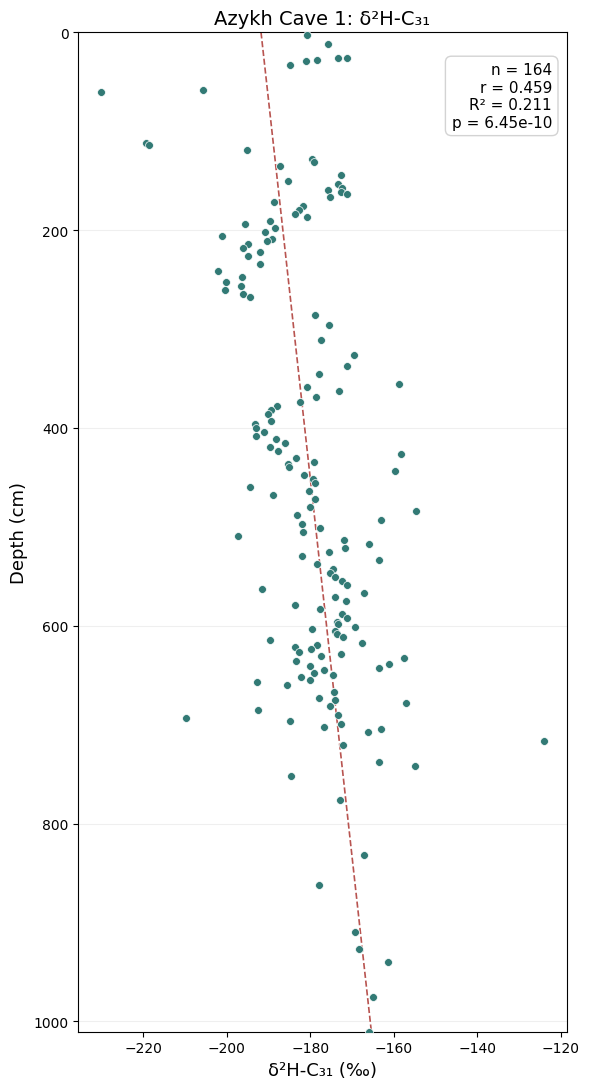


Analysis completed.


In [ ]:

# =====================================================
# AZYKH CAVE 1: δ²H-C31 vs STRATIGRAPHIC DEPTH
# Pearson r, R², p-value and Spearman correlation
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress, spearmanr
from google.colab import files
import io

# 1. Upload CSV or Excel
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_csv(
        io.BytesIO(uploaded[filename]),
        sep=None,
        engine="python",
        encoding="utf-8-sig"
    )

df.columns = df.columns.str.strip()

# 2. Exact dataset columns
depth_col = "Depth"
isotope_col = "δ H31 wax (‰)"

for col in [depth_col, isotope_col]:
    if col not in df.columns:
        raise ValueError(
            f"Missing column: {col}\n"
            f"Available columns: {df.columns.tolist()}"
        )

# 3. Convert to numeric
# Roof, Exterior and Guano have no numeric depth
df["Depth_cm"] = pd.to_numeric(
    df[depth_col].astype(str).str.replace(",", "."),
    errors="coerce"
)

df["H31"] = pd.to_numeric(
    df[isotope_col].astype(str).str.replace(",", "."),
    errors="coerce"
)

# 4. Select cave samples with valid values
data = df[
    df["Depth_cm"].between(0, 1010.5) &
    df["H31"].notna()
].copy()

data = data.sort_values("Depth_cm")

if len(data) < 3:
    raise ValueError("Not enough valid paired measurements.")

# 5. Correlation and regression
x = data["Depth_cm"].to_numpy()
y = data["H31"].to_numpy()

reg = linregress(x, y)
rho, spearman_p = spearmanr(x, y)

r = reg.rvalue
r2 = r ** 2

print("=" * 55)
print("δ²H-C31 vs DEPTH — AZYKH CAVE 1")
print("=" * 55)

print(f"Number of samples (n): {len(data)}")
print(f"Pearson r: {r:.4f}")
print(f"R²: {r2:.4f}")
print(f"Pearson p-value: {reg.pvalue:.6g}")
print(f"Spearman rho: {rho:.4f}")
print(f"Spearman p-value: {spearman_p:.6g}")
print(f"Regression slope: {reg.slope:.6f} ‰/cm")
print(f"Regression intercept: {reg.intercept:.4f} ‰")
print(f"Minimum δ²H-C31: {y.min():.2f} ‰")
print(f"Maximum δ²H-C31: {y.max():.2f} ‰")

# 6. Plot
fig, ax = plt.subplots(figsize=(6, 11))

ax.scatter(
    y, x,
    s=32,
    color="#327A75",
    edgecolor="white",
    linewidth=0.5,
    zorder=3
)

depth_line = np.linspace(0, 1010.5, 500)
isotope_line = reg.intercept + reg.slope * depth_line

ax.plot(
    isotope_line,
    depth_line,
    "--",
    color="#B85450",
    linewidth=1.2,
    label="Linear regression"
)

ax.set_ylim(1010.5, 0)
ax.set_xlabel("δ²H-C₃₁ (‰)", fontsize=13)
ax.set_ylabel("Depth (cm)", fontsize=13)
ax.set_title("Azykh Cave 1: δ²H-C₃₁", fontsize=14)

ax.grid(axis="y", alpha=0.2)

ax.text(
    0.97, 0.97,
    f"n = {len(data)}\n"
    f"r = {r:.3f}\n"
    f"R² = {r2:.3f}\n"
    f"p = {reg.pvalue:.3g}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11,
    bbox=dict(
        facecolor="white",
        edgecolor="lightgray",
        boxstyle="round,pad=0.4"
    )
)

plt.tight_layout()

plt.savefig(
    "Azykh_H31_Depth_Correlation.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Azykh_H31_Depth_Correlation.pdf",
    bbox_inches="tight"
)

plt.show()

# 7. Export the exact data used
data.to_csv(
    "Azykh_H31_Depth_Correlation_Data.csv",
    index=False
)

print("\nAnalysis completed.")


Upload your CSV or Excel dataset:


Saving hydrogen data.csv to hydrogen data (1).csv

Columns found:
['Depth', 'δ H31 wax (‰)', '± 1σ Propagated δ H31(‰)', 'δ H29 wax (‰)', '± 1σ Propagated δ H29 (‰)', 'Walls']

CAVE δ²H-C31 vs DEPTH
Cave samples (n): 164
Pearson r: 0.4588
R²: 0.2105
Pearson p-value: 6.45365e-10
Spearman rho: 0.4417
Spearman p-value: 3.21487e-09
Regression slope: 0.0261635 ‰/cm

MODERN REFERENCE SAMPLES
Roof: n=5, min=-180.99‰, max=-160.93‰, mean=-168.90‰
Exterior: n=2, min=-174.43‰, max=-139.54‰, mean=-156.98‰
Guano: n=1, min=-157.73‰, max=-157.73‰, mean=-157.73‰


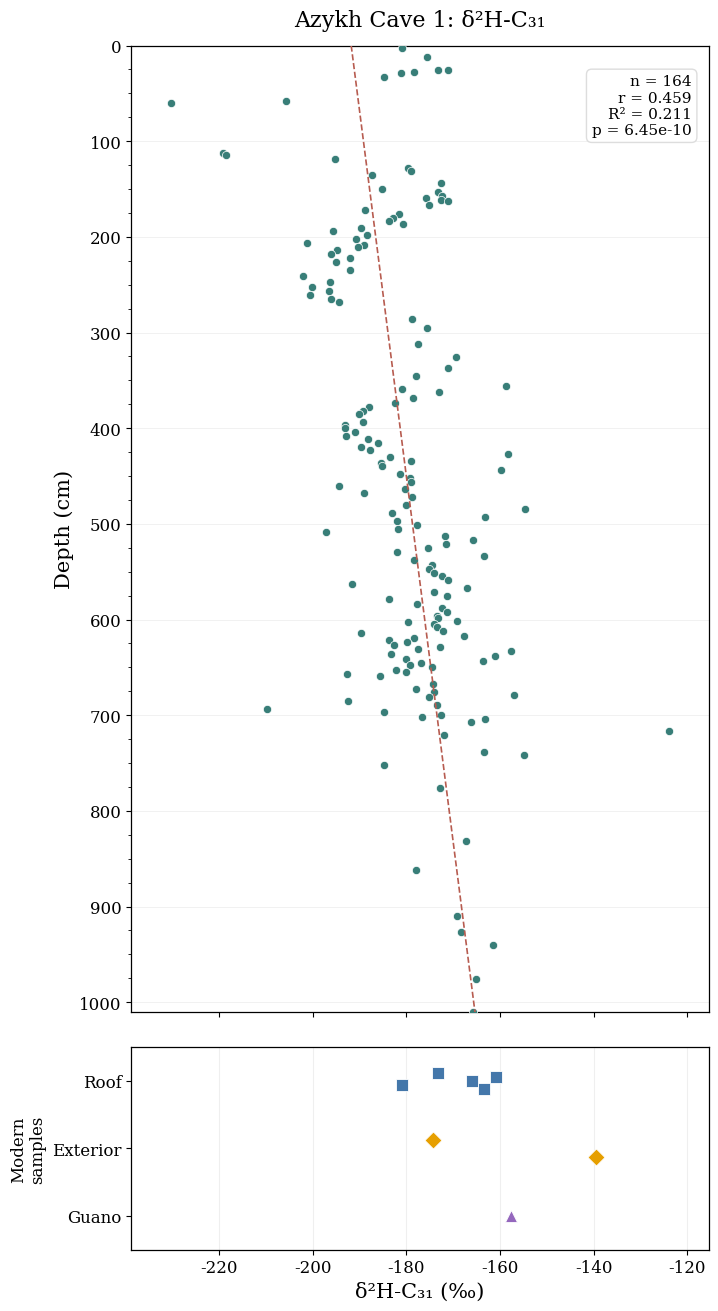

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Analysis completed successfully.


In [ ]:

# ============================================================
# AZYKH CAVE 1 — δ²H-C31 CORRELATION WITH DEPTH
# INCLUDING MODERN ROOF, EXTERIOR AND GUANO SAMPLES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import linregress, spearmanr
from google.colab import files
import io, os, zipfile

# ---------- SETTINGS ----------
OUTPUT = "Azykh_H31_Correlation"
os.makedirs(OUTPUT, exist_ok=True)

DEPTH_MAX = 1010.5
DPI = 600

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 0.9,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "axes.unicode_minus": False
})

# ---------- UPLOAD DATA ----------
print("Upload your CSV or Excel dataset:")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded.")

filename = next(iter(uploaded))

if filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_csv(
        io.BytesIO(uploaded[filename]),
        sep=None,
        engine="python",
        encoding="utf-8-sig"
    )

df.columns = df.columns.astype(str).str.strip()

print("\nColumns found:")
print(df.columns.tolist())

# ---------- REQUIRED COLUMNS ----------
DEPTH_COL = "Depth"
H31_COL = "δ H31 wax (‰)"

for col in [DEPTH_COL, H31_COL]:
    if col not in df.columns:
        raise ValueError(f"Missing column: {col}")

# ---------- CLEAN VALUES ----------
def to_numeric(series):
    return pd.to_numeric(
        series.astype(str)
        .str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

df["Depth_label"] = (
    df[DEPTH_COL].fillna("").astype(str).str.strip()
)

df["Depth_cm"] = to_numeric(df[DEPTH_COL])
df["H31"] = to_numeric(df[H31_COL])

# ---------- IDENTIFY SAMPLE GROUPS ----------
labels = df["Depth_label"].str.lower()

df["Group"] = "Cave"

df.loc[
    labels.str.contains("roof", na=False),
    "Group"
] = "Roof"

df.loc[
    labels.str.contains("exterior", na=False),
    "Group"
] = "Exterior"

df.loc[
    labels.str.contains("guano|gauno", regex=True, na=False),
    "Group"
] = "Guano"

# Cave: valid numerical depths and isotope values
cave = df[
    (df["Group"] == "Cave") &
    (df["Depth_cm"].between(0, DEPTH_MAX)) &
    (df["H31"].notna())
].copy()

# Modern: valid isotope values
modern = df[
    (df["Group"] != "Cave") &
    (df["H31"].notna())
].copy()

if len(cave) < 3:
    raise ValueError("Insufficient cave data for correlation.")

# ---------- CORRELATION ----------
x = cave["Depth_cm"].to_numpy()
y = cave["H31"].to_numpy()

reg = linregress(x, y)
rho, spearman_p = spearmanr(x, y)

r = reg.rvalue
r2 = r**2

print("\n" + "=" * 55)
print("CAVE δ²H-C31 vs DEPTH")
print("=" * 55)

print(f"Cave samples (n): {len(cave)}")
print(f"Pearson r: {r:.4f}")
print(f"R²: {r2:.4f}")
print(f"Pearson p-value: {reg.pvalue:.6g}")
print(f"Spearman rho: {rho:.4f}")
print(f"Spearman p-value: {spearman_p:.6g}")
print(f"Regression slope: {reg.slope:.7f} ‰/cm")

print("\nMODERN REFERENCE SAMPLES")
print("=" * 55)

for group in ["Roof", "Exterior", "Guano"]:
    values = modern.loc[
        modern["Group"] == group, "H31"
    ]

    if len(values):
        print(
            f"{group}: n={len(values)}, "
            f"min={values.min():.2f}‰, "
            f"max={values.max():.2f}‰, "
            f"mean={values.mean():.2f}‰"
        )
    else:
        print(f"{group}: no valid measurements")

# ---------- FIGURE ----------
fig = plt.figure(figsize=(7.5, 14))

gs = GridSpec(
    2, 1,
    height_ratios=[11, 2.3],
    hspace=0.06
)

ax = fig.add_subplot(gs[0])
ax_mod = fig.add_subplot(gs[1], sharex=ax)

# Cave points
ax.scatter(
    cave["H31"],
    cave["Depth_cm"],
    s=35,
    color="#387E78",
    edgecolor="white",
    linewidth=0.5,
    zorder=3
)

# Regression line
depth_line = np.linspace(0, DEPTH_MAX, 500)
h31_line = reg.intercept + reg.slope * depth_line

ax.plot(
    h31_line,
    depth_line,
    color="#B75C50",
    linestyle="--",
    linewidth=1.2,
    zorder=4
)

# Inverted depth
ax.set_ylim(DEPTH_MAX, 0)

ax.set_yticks(np.arange(0, 1001, 100))
ax.set_yticks(np.arange(0, 1001, 25), minor=True)

ax.set_ylabel("Depth (cm)", fontsize=15)
ax.set_title(
    "Azykh Cave 1: δ²H-C₃₁",
    fontsize=16,
    pad=14
)

ax.grid(
    axis="y",
    linewidth=0.5,
    alpha=0.25
)

ax.tick_params(axis="x", labelbottom=False)

# Correlation annotation
ax.text(
    0.97, 0.97,
    f"n = {len(cave)}\n"
    f"r = {r:.3f}\n"
    f"R² = {r2:.3f}\n"
    f"p = {reg.pvalue:.3g}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11,
    bbox=dict(
        facecolor="white",
        edgecolor="#DDDDDD",
        boxstyle="round,pad=0.35"
    )
)

# ---------- MODERN REFERENCE PANEL ----------
colors = {
    "Roof": "#4477AA",
    "Exterior": "#E69F00",
    "Guano": "#9467BD"
}

markers = {
    "Roof": "s",
    "Exterior": "D",
    "Guano": "^"
}

positions = {
    "Roof": 3,
    "Exterior": 2,
    "Guano": 1
}

for group in ["Roof", "Exterior", "Guano"]:

    sub = modern[modern["Group"] == group]

    if sub.empty:
        continue

    # Small vertical offsets to distinguish samples
    offsets = (
        np.linspace(-0.12, 0.12, len(sub))
        if len(sub) > 1 else np.array([0])
    )

    ax_mod.scatter(
        sub["H31"],
        positions[group] + offsets,
        color=colors[group],
        marker=markers[group],
        s=75,
        edgecolor="white",
        linewidth=0.6,
        zorder=3
    )

ax_mod.set_ylim(0.5, 3.5)
ax_mod.set_yticks([1, 2, 3])
ax_mod.set_yticklabels(["Guano", "Exterior", "Roof"])

ax_mod.set_xlabel("δ²H-C₃₁ (‰)", fontsize=15)
ax_mod.set_ylabel("Modern\nsamples", fontsize=12)

ax_mod.grid(axis="x", alpha=0.2)

# X range includes cave AND modern samples
all_h31 = pd.concat([
    cave["H31"],
    modern["H31"]
])

xmin = all_h31.min()
xmax = all_h31.max()
padding = (xmax - xmin) * 0.08

ax.set_xlim(xmin - padding, xmax + padding)

fig.subplots_adjust(
    left=0.19,
    right=0.96,
    top=0.94,
    bottom=0.08
)

# ---------- SAVE FIGURES ----------
for extension in ["png", "pdf", "svg"]:
    fig.savefig(
        os.path.join(
            OUTPUT,
            f"H31_Depth_Modern.{extension}"
        ),
        dpi=DPI,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()
plt.close(fig)

# ---------- EXPORT DATA ----------
cave.to_csv(
    os.path.join(OUTPUT, "Cave_H31_Regression_Data.csv"),
    index=False
)

modern.to_csv(
    os.path.join(OUTPUT, "Modern_H31_Data.csv"),
    index=False
)

statistics = pd.DataFrame([{
    "Proxy": "δ²H-C31",
    "Cave_n": len(cave),
    "Modern_n": len(modern),
    "Pearson_r": r,
    "R_squared": r2,
    "Pearson_p": reg.pvalue,
    "Spearman_rho": rho,
    "Spearman_p": spearman_p,
    "Slope_per_cm": reg.slope,
    "Intercept": reg.intercept
}])

statistics.to_csv(
    os.path.join(OUTPUT, "H31_Correlation_Statistics.csv"),
    index=False
)

# ---------- ZIP AND DOWNLOAD ----------
zip_name = "Azykh_H31_Correlation_Appendix.zip"

with zipfile.ZipFile(
    zip_name, "w", zipfile.ZIP_DEFLATED
) as archive:
    for name in os.listdir(OUTPUT):
        archive.write(
            os.path.join(OUTPUT, name),
            arcname=name
        )

files.download(zip_name)

print("\nAnalysis completed successfully.")


In [ ]:

# ==============================================================
# AZYKH CAVE 1 — COMPLETE δ²H-C31 RESULTS VERIFICATION
# Cave walls, three sections, correlation, modern samples
# ==============================================================

import pandas as pd
import numpy as np
import io
from scipy.stats import linregress, spearmanr
from google.colab import files

# 1. UPLOAD YOUR DATA
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_csv(
        io.BytesIO(uploaded[filename]),
        sep=None,
        engine="python",
        encoding="utf-8-sig"
    )

df.columns = df.columns.astype(str).str.strip()

# 2. DATASET COLUMN NAMES
DEPTH = "Depth"
ISOTOPE = "δ H31 wax (‰)"
WALLS = "Walls"

for col in [DEPTH, ISOTOPE, WALLS]:
    if col not in df.columns:
        raise ValueError(
            f"Column '{col}' missing. "
            f"Available columns: {df.columns.tolist()}"
        )

# 3. CLEAN DATA
def numeric(series):
    return pd.to_numeric(
        series.astype(str)
        .str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

df["Depth_cm"] = numeric(df[DEPTH])
df["H31"] = numeric(df[ISOTOPE])

def classify_wall(value):
    s = str(value).strip().lower()
    s = s.replace("wall", "").replace("w-", "").replace("w", "")
    s = s.replace(" ", "")
    roman = {"i":1, "ii":2, "iii":3, "iv":4, "v":5, "vi":6}
    if s in roman:
        return roman[s]
    try:
        n = int(float(s))
        return n if 1 <= n <= 6 else np.nan
    except (ValueError, TypeError):
        return np.nan

df["Wall_num"] = df[WALLS].apply(classify_wall)

# Modern labels may appear in Depth or Walls
labels = (
    df[DEPTH].fillna("").astype(str) + " " +
    df[WALLS].fillna("").astype(str)
).str.lower()

df["Modern_group"] = ""
df.loc[labels.str.contains("roof"), "Modern_group"] = "Roof"
df.loc[labels.str.contains("exterior"), "Modern_group"] = "Exterior"
df.loc[
    labels.str.contains("guano|gauno", regex=True),
    "Modern_group"
] = "Guano"

# 4. SEPARATE CAVE AND MODERN DATA
cave = df[
    df["Depth_cm"].between(0, 1010.5) &
    df["H31"].notna() &
    df["Modern_group"].eq("")
].copy()

modern = df[
    df["Modern_group"].ne("") &
    df["H31"].notna()
].copy()

if len(cave) < 3:
    raise ValueError("Fewer than 3 valid cave samples.")

# Warn about cave rows missing wall assignments
missing_wall = cave["Wall_num"].isna().sum()

print(f"Valid cave isotope measurements: {len(cave)}")
print(f"Valid modern measurements: {len(modern)}")
print(f"Cave measurements without recognized wall: {missing_wall}")

if missing_wall:
    print("\nWARNING: These cave rows need wall labels:")
    print(
        cave.loc[
            cave["Wall_num"].isna(),
            [DEPTH, ISOTOPE, WALLS]
        ].to_string(index=False)
    )

# 5. COMPLETE CORRELATION
reg = linregress(cave["Depth_cm"], cave["H31"])
rho, p_spearman = spearmanr(
    cave["Depth_cm"], cave["H31"]
)

r = reg.rvalue
r2 = r ** 2

correlation = pd.DataFrame([{
    "Samples_n": len(cave),
    "Pearson_r": r,
    "R_squared": r2,
    "Pearson_p": reg.pvalue,
    "Spearman_rho": rho,
    "Spearman_p": p_spearman,
    "Slope_per_cm": reg.slope,
    "Intercept": reg.intercept
}])

print("\n" + "=" * 65)
print("1. CORRELATION WITH DEPTH")
print("=" * 65)
print(correlation.round(5).to_string(index=False))

if reg.slope > 0:
    print(
        "\nDirection: isotope values become more positive "
        "with increasing depth."
    )
elif reg.slope < 0:
    print(
        "\nDirection: isotope values become more negative "
        "with increasing depth."
    )

# 6. OVERALL ISOTOPE STATISTICS
overall = pd.DataFrame([{
    "Group": "All cave samples",
    "n": len(cave),
    "Minimum": cave["H31"].min(),
    "Maximum": cave["H31"].max(),
    "Mean": cave["H31"].mean(),
    "Median": cave["H31"].median(),
    "SD": cave["H31"].std(),
    "Range": cave["H31"].max() - cave["H31"].min()
}])

print("\n" + "=" * 65)
print("2. OVERALL ISOTOPE DISTRIBUTION (‰)")
print("=" * 65)
print(overall.round(2).to_string(index=False))

# 7. WALL-BY-WALL STATISTICS
wall_stats = (
    cave.dropna(subset=["Wall_num"])
    .groupby("Wall_num")["H31"]
    .agg(
        n="count",
        Minimum="min",
        Maximum="max",
        Mean="mean",
        Median="median",
        SD="std"
    )
    .reset_index()
)

wall_stats["Range"] = (
    wall_stats["Maximum"] - wall_stats["Minimum"]
)

wall_stats["Wall"] = (
    "Wall " + wall_stats["Wall_num"].astype(int).astype(str)
)

wall_stats = wall_stats[
    ["Wall", "n", "Minimum", "Maximum",
     "Mean", "Median", "SD", "Range"]
].sort_values("Wall", ascending=False)

print("\n" + "=" * 65)
print("3. ISOTOPE STATISTICS FOR EACH WALL (‰)")
print("=" * 65)
print(wall_stats.round(2).to_string(index=False))

# 8. THREE STRATIGRAPHIC SECTIONS
def section(wall):
    if pd.isna(wall):
        return np.nan
    if wall in [4, 5, 6]:
        return "Lower (Walls 6-4)"
    if wall in [2, 3]:
        return "Middle (Walls 3-2)"
    if wall == 1:
        return "Upper (Wall 1)"
    return np.nan

cave["Section"] = cave["Wall_num"].apply(section)

section_stats = (
    cave.dropna(subset=["Section"])
    .groupby("Section")["H31"]
    .agg(
        n="count",
        Minimum="min",
        Maximum="max",
        Mean="mean",
        Median="median",
        SD="std"
    )
    .reset_index()
)

section_stats["Range"] = (
    section_stats["Maximum"] - section_stats["Minimum"]
)

section_order = [
    "Lower (Walls 6-4)",
    "Middle (Walls 3-2)",
    "Upper (Wall 1)"
]

section_stats["Section"] = pd.Categorical(
    section_stats["Section"],
    categories=section_order,
    ordered=True
)

section_stats = section_stats.sort_values("Section")

print("\n" + "=" * 65)
print("4. LOWER, MIDDLE AND UPPER SECTIONS (‰)")
print("=" * 65)
print(section_stats.round(2).to_string(index=False))

# 9. MODERN REFERENCE STATISTICS
modern_stats = (
    modern.groupby("Modern_group")["H31"]
    .agg(
        n="count",
        Minimum="min",
        Maximum="max",
        Mean="mean",
        Median="median",
        SD="std"
    )
    .reset_index()
)

modern_stats["Range"] = (
    modern_stats["Maximum"] - modern_stats["Minimum"]
)

print("\n" + "=" * 65)
print("5. MODERN REFERENCE SAMPLES (‰)")
print("=" * 65)
print(modern_stats.round(2).to_string(index=False))

# 10. VERIFY EVERY NUMBER REPORTED IN YOUR PARAGRAPH
checks = []

def add_check(description, reported, calculated, tolerance=0.015):
    if pd.isna(calculated):
        status = "NOT VERIFIED"
    elif abs(reported - calculated) <= tolerance:
        status = "MATCH"
    else:
        status = "MISMATCH"

    checks.append({
        "Description": description,
        "Reported": reported,
        "Calculated": calculated,
        "Difference": (
            calculated - reported
            if pd.notna(calculated) else np.nan
        ),
        "Status": status
    })

add_check("Overall minimum", -230.25, cave["H31"].min())
add_check("Overall maximum", -123.92, cave["H31"].max())
add_check("R squared", 0.211, r2, tolerance=0.0015)

for wall, reported_min, reported_max in [
    (6, -177.93, -161.42),
    (5, -209.83, -123.92),
    (1, -230.25, -171.19)
]:
    sub = cave[cave["Wall_num"] == wall]
    add_check(
        f"Wall {wall} minimum",
        reported_min,
        sub["H31"].min()
    )
    add_check(
        f"Wall {wall} maximum",
        reported_max,
        sub["H31"].max()
    )

for group, reported_min, reported_max in [
    ("Roof", -180.99, -160.93),
    ("Exterior", -174.43, -139.54),
    ("Guano", -157.73, -157.73)
]:
    sub = modern[modern["Modern_group"] == group]
    add_check(
        f"{group} minimum",
        reported_min,
        sub["H31"].min()
    )
    add_check(
        f"{group} maximum",
        reported_max,
        sub["H31"].max()
    )

verification = pd.DataFrame(checks)

print("\n" + "=" * 65)
print("6. CHECK OF YOUR WRITTEN RESULTS")
print("=" * 65)
print(verification.round(4).to_string(index=False))

# 11. CHECK CLAIMS ABOUT WALL VARIABILITY
print("\n" + "=" * 65)
print("7. VARIABILITY CHECK")
print("=" * 65)

ranges = dict(zip(
    wall_stats["Wall"],
    wall_stats["Range"]
))

if "Wall 4" in ranges and "Wall 5" in ranges:
    print(
        "Wall 4 narrower than Wall 5:",
        ranges["Wall 4"] < ranges["Wall 5"]
    )

if all(f"Wall {w}" in ranges for w in [1, 2, 3]):
    print(
        "Wall 1 wider than Walls 2 and 3:",
        ranges["Wall 1"] > ranges["Wall 2"]
        and ranges["Wall 1"] > ranges["Wall 3"]
    )

print(
    "Wall with largest isotope range:",
    max(ranges, key=ranges.get) if ranges else "Unavailable"
)

print(
    "Wall with smallest isotope range:",
    min(ranges, key=ranges.get) if ranges else "Unavailable"
)

# 12. IDENTIFY EXTREME SAMPLES
print("\n" + "=" * 65)
print("8. MOST DEPLETED AND ENRICHED SAMPLES")
print("=" * 65)

cols = [c for c in ["Sample ID", "Depth_cm", WALLS, "H31"]
        if c in cave.columns]

print("\nFive most depleted:")
print(cave.nsmallest(5, "H31")[cols].to_string(index=False))

print("\nFive most enriched:")
print(cave.nlargest(5, "H31")[cols].to_string(index=False))

# 13. SAVE ALL RESULTS
output = "Azykh_H31_Full_Results_Verification.xlsx"

with pd.ExcelWriter(output, engine="openpyxl") as writer:
    correlation.to_excel(
        writer, sheet_name="Correlation", index=False
    )
    overall.to_excel(
        writer, sheet_name="Overall", index=False
    )
    wall_stats.to_excel(
        writer, sheet_name="Wall Statistics", index=False
    )
    section_stats.to_excel(
        writer, sheet_name="Three Sections", index=False
    )
    modern_stats.to_excel(
        writer, sheet_name="Modern Samples", index=False
    )
    verification.to_excel(
        writer, sheet_name="Text Verification", index=False
    )
    cave.to_excel(
        writer, sheet_name="Cave Raw Data", index=False
    )
    modern.to_excel(
        writer, sheet_name="Modern Raw Data", index=False
    )

verification.to_csv(
    "Azykh_H31_Text_Verification.csv",
    index=False
)

files.download(output)
files.download("Azykh_H31_Text_Verification.csv")

print("\nVerification complete.")


Saving hydrogen data.csv to hydrogen data (2).csv
Valid cave isotope measurements: 164
Valid modern measurements: 8
Cave measurements without recognized wall: 0

1. CORRELATION WITH DEPTH
 Samples_n  Pearson_r  R_squared  Pearson_p  Spearman_rho  Spearman_p  Slope_per_cm  Intercept
       164    0.45883    0.21053        0.0       0.44168         0.0       0.02616 -191.80577

Direction: isotope values become more positive with increasing depth.

2. OVERALL ISOTOPE DISTRIBUTION (‰)
           Group   n  Minimum  Maximum    Mean  Median    SD  Range
All cave samples 164  -230.25  -123.92 -180.05  -179.0 12.91 106.32

3. ISOTOPE STATISTICS FOR EACH WALL (‰)
  Wall  n  Minimum  Maximum    Mean  Median    SD  Range
Wall 6  7  -177.93  -161.42 -167.86 -167.19  5.13  16.51
Wall 5 45  -209.83  -123.92 -174.68 -174.48 12.78  85.91
Wall 4 39  -197.24  -154.72 -176.71 -177.65  8.95  42.52
Wall 3 25  -193.18  -158.24 -181.79 -183.48  9.93  34.94
Wall 2 25  -202.14  -178.78 -191.91 -192.04  6.58  2

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Verification complete.


In [ ]:

# ============================================================
# AZYKH CAVE 1 — COMPLETE PAH RESULTS VERIFICATION
# Total PAHs, hPAHs, IPAHs, walls and modern samples
# ============================================================

import pandas as pd
import numpy as np
import io
from scipy.stats import linregress, spearmanr
from google.colab import files

# ---------- 1. UPLOAD ----------
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_csv(
        io.BytesIO(uploaded[filename]),
        sep=None,
        engine="python",
        encoding="utf-8-sig"
    )

df.columns = df.columns.astype(str).str.strip()

print("Columns found:")
print(df.columns.tolist())

# ---------- 2. COLUMN NAMES ----------
DEPTH = "Depth"
WALL = "Walls"

PROXIES = {
    "Total PAHs": "[PAHs]\\(ng/g)",
    "hPAHs": "hPAHs  (ng/g)",
    "IPAHs": "IPAHs(ng/g)"
}

# Match column names ignoring spaces
def find_column(name):
    def normalize(s):
        return "".join(str(s).split()).lower()

    matches = [
        col for col in df.columns
        if normalize(col) == normalize(name)
    ]
    if not matches:
        raise ValueError(
            f"Column not found: {name}\n"
            f"Available: {df.columns.tolist()}"
        )
    return matches[0]

depth_col = find_column(DEPTH)
wall_col = find_column(WALL)
proxy_cols = {
    name: find_column(col)
    for name, col in PROXIES.items()
}

# ---------- 3. CLEAN NUMBERS ----------
def numeric(series):
    return pd.to_numeric(
        series.astype(str)
        .str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

df["Depth_cm"] = numeric(df[depth_col])

for name, col in proxy_cols.items():
    df[name] = numeric(df[col])

# ---------- 4. CLASSIFY WALLS ----------
def classify_wall(value):
    s = str(value).strip().lower()
    s = s.replace("wall", "").replace("w-", "")
    s = s.replace(" ", "")

    roman = {
        "i": 1, "ii": 2, "iii": 3,
        "iv": 4, "v": 5, "vi": 6
    }

    if s in roman:
        return roman[s]

    try:
        n = int(float(s))
        return n if 1 <= n <= 6 else np.nan
    except (ValueError, TypeError):
        return np.nan

df["Wall_num"] = df[wall_col].apply(classify_wall)

# Modern samples may be labelled in Depth or Walls
labels = (
    df[depth_col].fillna("").astype(str) + " " +
    df[wall_col].fillna("").astype(str)
).str.lower()

df["Modern_group"] = ""

df.loc[
    labels.str.contains("roof"),
    "Modern_group"
] = "Roof"

df.loc[
    labels.str.contains("exterior"),
    "Modern_group"
] = "Exterior"

df.loc[
    labels.str.contains("guano|gauno", regex=True),
    "Modern_group"
] = "Guano"

# ---------- 5. SELECT SAMPLES ----------
cave = df[
    df["Depth_cm"].between(0, 1010.5) &
    df["Modern_group"].eq("")
].copy()

modern = df[
    df["Modern_group"].ne("")
].copy()

print("\nCave rows:", len(cave))
print("Modern rows:", len(modern))

missing_walls = cave["Wall_num"].isna().sum()
print("Cave rows without recognized wall:", missing_walls)

if missing_walls:
    print(
        cave.loc[
            cave["Wall_num"].isna(),
            [depth_col, wall_col]
        ].to_string(index=False)
    )

# ---------- 6. STATISTICS FUNCTION ----------
def summary(data, group_col, proxy):
    result = (
        data.dropna(subset=[proxy])
        .groupby(group_col)[proxy]
        .agg(
            n="count",
            Minimum="min",
            Maximum="max",
            Mean="mean",
            Median="median",
            SD="std"
        )
        .reset_index()
    )

    result["Range"] = (
        result["Maximum"] - result["Minimum"]
    )

    return result

# ---------- 7. STRATIGRAPHIC SECTIONS ----------
def section(w):
    if pd.isna(w):
        return np.nan
    if w in [4, 5, 6]:
        return "Lower (Walls 6-4)"
    if w in [2, 3]:
        return "Middle (Walls 3-2)"
    if w == 1:
        return "Upper (Wall 1)"
    return np.nan

cave["Section"] = cave["Wall_num"].apply(section)

# ---------- 8. ANALYSE EACH PROXY ----------
correlations = []
overall_tables = []
wall_tables = []
section_tables = []
modern_tables = []
extreme_tables = []

reported_r2 = {
    "Total PAHs": 0.003,
    "hPAHs": 0.235,
    "IPAHs": 0.040
}

for proxy in PROXIES:

    sub = cave.dropna(
        subset=["Depth_cm", proxy]
    ).copy()

    if len(sub) < 3:
        print(f"\nInsufficient data for {proxy}")
        continue

    x = sub["Depth_cm"].to_numpy()
    y = sub[proxy].to_numpy()

    reg = linregress(x, y)
    rho, sp = spearmanr(x, y)

    r2 = reg.rvalue ** 2

    correlations.append({
        "Proxy": proxy,
        "n": len(sub),
        "Pearson_r": reg.rvalue,
        "R_squared": r2,
        "Pearson_p": reg.pvalue,
        "Spearman_rho": rho,
        "Spearman_p": sp,
        "Slope_per_cm": reg.slope,
        "Intercept": reg.intercept,
        "Reported_R2": reported_r2[proxy],
        "R2_difference": r2 - reported_r2[proxy],
        "R2_check": (
            "MATCH"
            if abs(r2 - reported_r2[proxy]) <= 0.0015
            else "MISMATCH"
        )
    })

    overall_tables.append({
        "Proxy": proxy,
        "n": len(sub),
        "Minimum": y.min(),
        "Maximum": y.max(),
        "Mean": y.mean(),
        "Median": np.median(y),
        "SD": np.std(y, ddof=1),
        "Range": y.max() - y.min(),
        "Zero_count": np.sum(y == 0),
        "Negative_count": np.sum(y < 0)
    })

    wt = summary(
        sub.dropna(subset=["Wall_num"]),
        "Wall_num", proxy
    )
    wt.insert(0, "Proxy", proxy)
    wall_tables.append(wt)

    st = summary(
        sub.dropna(subset=["Section"]),
        "Section", proxy
    )
    st.insert(0, "Proxy", proxy)
    section_tables.append(st)

    mt = summary(
        modern,
        "Modern_group", proxy
    )
    mt.insert(0, "Proxy", proxy)
    modern_tables.append(mt)

    cols = [
        c for c in [
            "Sample ID", "Depth_cm", wall_col, proxy
        ] if c in sub.columns
    ]

    highest = sub.nlargest(5, proxy)[cols].copy()
    highest.insert(0, "Extreme", "Highest")
    highest.insert(0, "Proxy", proxy)

    lowest = sub.nsmallest(5, proxy)[cols].copy()
    lowest.insert(0, "Extreme", "Lowest")
    lowest.insert(0, "Proxy", proxy)

    highest = highest.rename(
        columns={proxy: "Concentration"}
    )
    lowest = lowest.rename(
        columns={proxy: "Concentration"}
    )

    extreme_tables.extend([highest, lowest])

# ---------- 9. COMBINE TABLES ----------
correlation_df = pd.DataFrame(correlations)
overall_df = pd.DataFrame(overall_tables)

wall_df = pd.concat(
    wall_tables, ignore_index=True
)

section_df = pd.concat(
    section_tables, ignore_index=True
)

modern_df = pd.concat(
    modern_tables, ignore_index=True
)

extreme_df = pd.concat(
    extreme_tables, ignore_index=True
)

# ---------- 10. PRINT RESULTS ----------
def show(title, table):
    print("\n" + "=" * 75)
    print(title)
    print("=" * 75)
    print(table.round(5).to_string(index=False))

show("1. CORRELATIONS WITH DEPTH", correlation_df)
show("2. OVERALL CONCENTRATIONS", overall_df)
show("3. CONCENTRATIONS FOR EACH WALL", wall_df)
show("4. LOWER, MIDDLE AND UPPER SECTIONS", section_df)
show("5. MODERN REFERENCE SAMPLES", modern_df)
show("6. HIGHEST AND LOWEST VALUES", extreme_df)

# ---------- 11. QUALITY CHECK ----------
print("\n" + "=" * 75)
print("7. QUALITY CONTROL")
print("=" * 75)

for proxy in PROXIES:
    values = cave[proxy]

    print(f"\n{proxy}")
    print("Missing values:", values.isna().sum())
    print("Zero values:", (values == 0).sum())
    print("Negative values:", (values < 0).sum())

    if (values < 0).any():
        print(
            "WARNING: Negative concentrations detected. "
            "Check blank correction and data processing."
        )

# ---------- 12. EXPORT ----------
output = "Azykh_PAH_Complete_Verification.xlsx"

with pd.ExcelWriter(output, engine="openpyxl") as writer:

    correlation_df.to_excel(
        writer, "Correlations", index=False
    )

    overall_df.to_excel(
        writer, "Overall Statistics", index=False
    )

    wall_df.to_excel(
        writer, "Wall Statistics", index=False
    )

    section_df.to_excel(
        writer, "Three Sections", index=False
    )

    modern_df.to_excel(
        writer, "Modern Samples", index=False
    )

    extreme_df.to_excel(
        writer, "Extreme Values", index=False
    )

    cave.to_excel(
        writer, "Cave Data", index=False
    )

    modern.to_excel(
        writer, "Modern Data", index=False
    )

files.download(output)

print("\nComplete PAH verification finished.")


Saving PAHs data.csv to PAHs data.csv
Columns found:
['Serial', 'Sample', 'Depth', 'DMP(x)', 'DMP(y)', 'LMW/total', 'Ret/3-ring', '[PAHs](ng/g)', 'hPAHs  (ng/g)', 'IPAHs(ng/g)', 'Walls']


ValueError: Column not found: [PAHs]\(ng/g)
Available: ['Serial', 'Sample', 'Depth', 'DMP(x)', 'DMP(y)', 'LMW/total', 'Ret/3-ring', '[PAHs](ng/g)', 'hPAHs  (ng/g)', 'IPAHs(ng/g)', 'Walls']

Saving PAHs data.csv to PAHs data (1).csv
Detected columns:
['Serial', 'Sample', 'Depth', 'DMP(x)', 'DMP(y)', 'LMW/total', 'Ret/3-ring', '[PAHs](ng/g)', 'hPAHs  (ng/g)', 'IPAHs(ng/g)', 'Walls']

Matched PAH columns:
Total PAHs: '[PAHs](ng/g)'
hPAHs: 'hPAHs  (ng/g)'
IPAHs: 'IPAHs(ng/g)'

Cave rows: 227
Modern rows: 7

Modern sample counts:
Modern_group
Roof        5
Exterior    2
Name: count, dtype: int64

Cave samples without wall labels:
0

1. CORRELATION WITH DEPTH
     Proxy   n  Pearson_r  R_squared  Pearson_p  Spearman_rho  Spearman_p  Slope_per_cm  Reported_R2  R2_difference R2_check
Total PAHs 227    -0.0560     0.0031     0.4006        0.0608      0.3621       -0.0013        0.003         0.0001    MATCH
     hPAHs 227     0.4803     0.2307     0.0000        0.5942      0.0000        0.0028        0.235        -0.0043 MISMATCH
     IPAHs 227    -0.2020     0.0408     0.0022       -0.1897      0.0041       -0.0017        0.040         0.0008    MATCH

2. OVERALL PAH STATISTICS (

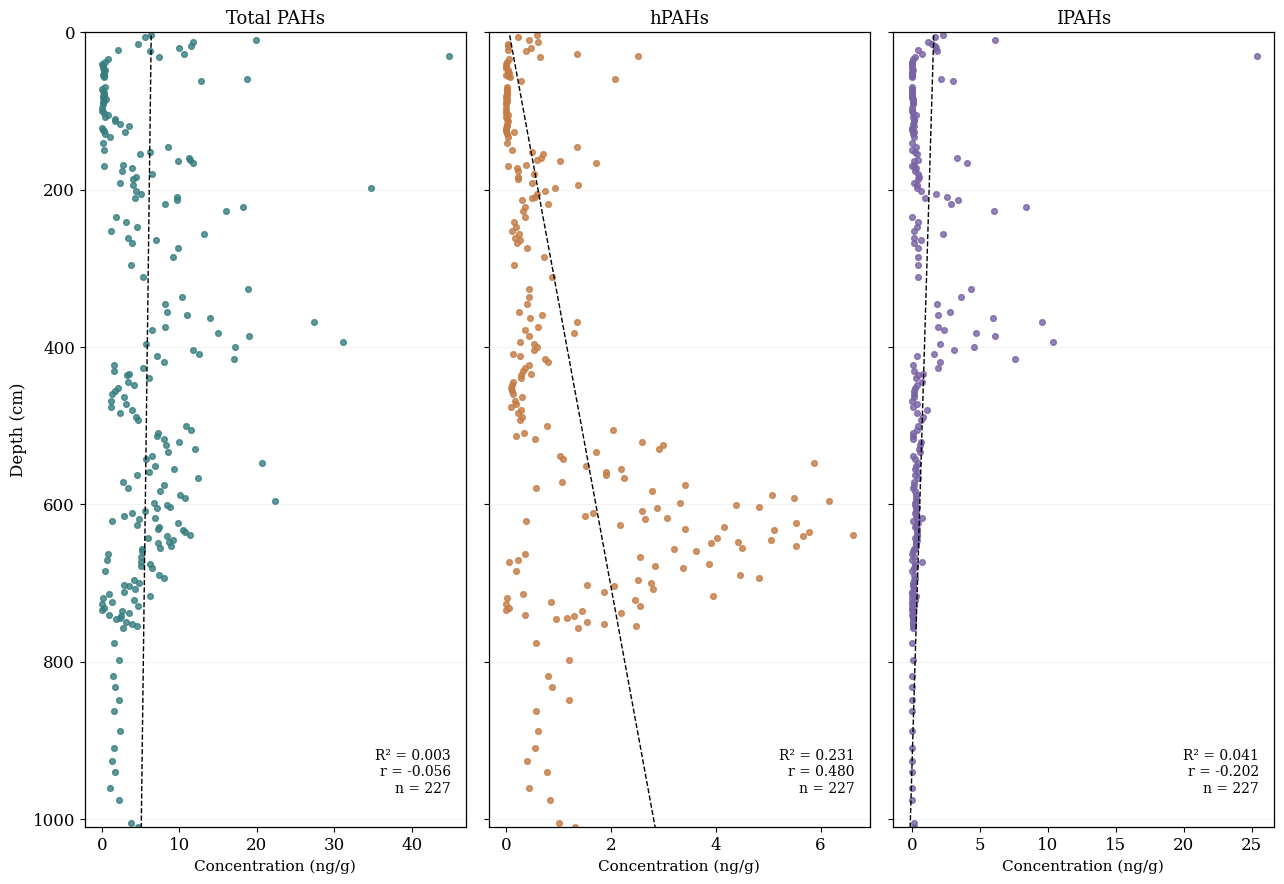

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PAH verification completed successfully.


In [ ]:

# ==============================================================
# AZYKH CAVE 1 — PAH COMPLETE STATISTICAL VERIFICATION
# Total PAHs, hPAHs, IPAHs
# ==============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io
import re
from scipy.stats import linregress, spearmanr
from google.colab import files

# 1. UPLOAD CSV OR EXCEL
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_csv(
        io.BytesIO(uploaded[filename]),
        sep=None,
        engine="python",
        encoding="utf-8-sig"
    )

df.columns = df.columns.astype(str).str.strip()

print("Detected columns:")
print(df.columns.tolist())

# 2. IDENTIFY THE THREE PAH COLUMNS AUTOMATICALLY
# Removes spaces, backslashes and punctuation for matching.

def normalize(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

def find_column(expected):
    matches = [
        c for c in df.columns
        if normalize(c) == normalize(expected)
    ]
    if not matches:
        raise ValueError(
            f"Could not find {expected}. "
            f"Available columns: {df.columns.tolist()}"
        )
    return matches[0]

depth_col = find_column("Depth")
wall_col = find_column("Walls")

pah_columns = {
    "Total PAHs": find_column("[PAHs](ng/g)"),
    "hPAHs": find_column("hPAHs(ng/g)"),
    "IPAHs": find_column("IPAHs(ng/g)")
}

print("\nMatched PAH columns:")
for proxy, col in pah_columns.items():
    print(f"{proxy}: {col!r}")

# 3. CLEAN NUMERIC DATA
def numeric(series):
    return pd.to_numeric(
        series.astype(str)
        .str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

df["Depth_cm"] = numeric(df[depth_col])

for proxy, col in pah_columns.items():
    df[proxy] = numeric(df[col])

# 4. IDENTIFY MODERN SAMPLES
# Search both Depth and Walls, plus Sample if available.

label_cols = [depth_col, wall_col]

if "Sample" in df.columns:
    label_cols.append("Sample")

labels = (
    df[label_cols]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.lower()
)

df["Modern_group"] = ""

df.loc[
    labels.str.contains("roof", na=False),
    "Modern_group"
] = "Roof"

df.loc[
    labels.str.contains("exterior", na=False),
    "Modern_group"
] = "Exterior"

df.loc[
    labels.str.contains("guano|gauno", regex=True, na=False),
    "Modern_group"
] = "Guano"

# 5. IDENTIFY WALLS
def get_wall(value):
    s = str(value).strip().lower()

    s = re.sub(r"^wall\s*", "", s)
    s = re.sub(r"^w[-\s]*", "", s)
    s = s.strip()

    roman = {
        "i": 1, "ii": 2, "iii": 3,
        "iv": 4, "v": 5, "vi": 6
    }

    if s in roman:
        return roman[s]

    try:
        n = int(float(s))
        return n if 1 <= n <= 6 else np.nan
    except (ValueError, TypeError):
        return np.nan

df["Wall_num"] = df[wall_col].apply(get_wall)

# 6. SEPARATE CAVE AND MODERN SAMPLES
cave = df[
    df["Depth_cm"].between(0, 1010.5) &
    df["Modern_group"].eq("")
].copy()

modern = df[
    df["Modern_group"].ne("")
].copy()

print("\nCave rows:", len(cave))
print("Modern rows:", len(modern))

print("\nModern sample counts:")
print(modern["Modern_group"].value_counts())

print("\nCave samples without wall labels:")
print(cave["Wall_num"].isna().sum())

# 7. STATISTICAL SUMMARY FUNCTION
def stats_table(data, group_column, proxy):
    result = (
        data.dropna(subset=[proxy])
        .groupby(group_column)[proxy]
        .agg(
            n="count",
            Minimum="min",
            Maximum="max",
            Mean="mean",
            Median="median",
            SD="std"
        )
        .reset_index()
    )

    result["Range"] = (
        result["Maximum"] - result["Minimum"]
    )

    return result

# 8. DEFINE THREE SECTIONS
def get_section(w):
    if pd.isna(w):
        return np.nan
    if w in [4, 5, 6]:
        return "Lower (Walls 6-4)"
    if w in [2, 3]:
        return "Middle (Walls 3-2)"
    if w == 1:
        return "Upper (Wall 1)"
    return np.nan

cave["Section"] = cave["Wall_num"].apply(get_section)

# 9. ANALYSE ALL THREE PROXIES
reported_r2 = {
    "Total PAHs": 0.003,
    "hPAHs": 0.235,
    "IPAHs": 0.040
}

correlation_results = []
overall_results = []
wall_results = []
section_results = []
modern_results = []
extreme_results = []

for proxy in pah_columns:

    sub = cave.dropna(
        subset=["Depth_cm", proxy]
    ).copy()

    if len(sub) < 3:
        print(f"Insufficient data for {proxy}")
        continue

    x = sub["Depth_cm"].to_numpy()
    y = sub[proxy].to_numpy()

    reg = linregress(x, y)
    rho, spearman_p = spearmanr(x, y)

    r2 = reg.rvalue ** 2

    correlation_results.append({
        "Proxy": proxy,
        "n": len(sub),
        "Pearson_r": reg.rvalue,
        "R_squared": r2,
        "Pearson_p": reg.pvalue,
        "Spearman_rho": rho,
        "Spearman_p": spearman_p,
        "Slope_per_cm": reg.slope,
        "Reported_R2": reported_r2[proxy],
        "R2_difference": r2 - reported_r2[proxy],
        "R2_check": (
            "MATCH"
            if abs(r2 - reported_r2[proxy]) <= 0.0015
            else "MISMATCH"
        )
    })

    overall_results.append({
        "Proxy": proxy,
        "n": len(sub),
        "Minimum": y.min(),
        "Maximum": y.max(),
        "Mean": y.mean(),
        "Median": np.median(y),
        "SD": np.std(y, ddof=1),
        "Range": y.max() - y.min(),
        "Zeros": np.sum(y == 0),
        "Negatives": np.sum(y < 0)
    })

    wt = stats_table(
        sub.dropna(subset=["Wall_num"]),
        "Wall_num",
        proxy
    )
    wt.insert(0, "Proxy", proxy)
    wall_results.append(wt)

    st = stats_table(
        sub.dropna(subset=["Section"]),
        "Section",
        proxy
    )
    st.insert(0, "Proxy", proxy)
    section_results.append(st)

    mt = stats_table(
        modern,
        "Modern_group",
        proxy
    )
    mt.insert(0, "Proxy", proxy)
    modern_results.append(mt)

    id_cols = [
        c for c in [
            "Serial", "Sample", "Depth_cm",
            wall_col, proxy
        ] if c in sub.columns
    ]

    high = sub.nlargest(5, proxy)[id_cols].copy()
    low = sub.nsmallest(5, proxy)[id_cols].copy()

    for table, label in [(high, "Highest"), (low, "Lowest")]:
        table.insert(0, "Extreme", label)
        table.insert(0, "Proxy", proxy)
        table.rename(
            columns={proxy: "Concentration_ng_g"},
            inplace=True
        )
        extreme_results.append(table)

# 10. COMBINE RESULTS
correlations = pd.DataFrame(correlation_results)
overall = pd.DataFrame(overall_results)
walls = pd.concat(wall_results, ignore_index=True)
sections = pd.concat(section_results, ignore_index=True)
modern_stats = pd.concat(modern_results, ignore_index=True)
extremes = pd.concat(extreme_results, ignore_index=True)

# 11. DISPLAY RESULTS
def display_table(title, table):
    print("\n" + "=" * 75)
    print(title)
    print("=" * 75)
    print(table.round(4).to_string(index=False))

display_table("1. CORRELATION WITH DEPTH", correlations)
display_table("2. OVERALL PAH STATISTICS (ng/g)", overall)
display_table("3. WALL-BY-WALL PAH STATISTICS", walls)
display_table("4. THREE STRATIGRAPHIC SECTIONS", sections)
display_table("5. MODERN REFERENCE SAMPLES", modern_stats)
display_table("6. HIGHEST AND LOWEST PAH CONCENTRATIONS", extremes)

# 12. QUALITY CONTROL
print("\n" + "=" * 75)
print("7. DATA QUALITY CHECK")
print("=" * 75)

for proxy in pah_columns:
    print(f"\n{proxy}")
    print("Valid cave values:", cave[proxy].notna().sum())
    print("Missing cave values:", cave[proxy].isna().sum())
    print("Zero concentrations:", (cave[proxy] == 0).sum())
    print("Negative concentrations:", (cave[proxy] < 0).sum())

    if (cave[proxy] < 0).any():
        print("WARNING: Negative concentration values found.")

# 13. OPTIONAL CORRELATION FIGURE
fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 9),
    sharey=True
)

colors = ["#377E80", "#C47B44", "#7962A5"]

for ax, proxy, color in zip(
    axes, pah_columns, colors
):
    sub = cave.dropna(
        subset=["Depth_cm", proxy]
    )

    x = sub["Depth_cm"].to_numpy()
    y = sub[proxy].to_numpy()

    reg = linregress(x, y)

    ax.scatter(
        y, x,
        s=17,
        color=color,
        alpha=0.8
    )

    depth_line = np.linspace(
        x.min(), x.max(), 300
    )

    ax.plot(
        reg.intercept + reg.slope * depth_line,
        depth_line,
        color="black",
        linewidth=1,
        linestyle="--"
    )

    ax.set_title(proxy, fontsize=13)
    ax.set_xlabel("Concentration (ng/g)", fontsize=11)

    ax.text(
        0.96, 0.04,
        f"R² = {reg.rvalue**2:.3f}\n"
        f"r = {reg.rvalue:.3f}\n"
        f"n = {len(sub)}",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10
    )

    ax.grid(axis="y", alpha=0.15)

axes[0].set_ylabel("Depth (cm)", fontsize=12)
axes[0].set_ylim(1010.5, 0)

plt.tight_layout()

plt.savefig(
    "Azykh_PAH_Depth_Correlation.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# 14. EXPORT TO EXCEL
output = "Azykh_PAH_Complete_Verification.xlsx"

with pd.ExcelWriter(output, engine="openpyxl") as writer:
    correlations.to_excel(
        writer, sheet_name="Correlations", index=False
    )
    overall.to_excel(
        writer, sheet_name="Overall", index=False
    )
    walls.to_excel(
        writer, sheet_name="Walls", index=False
    )
    sections.to_excel(
        writer, sheet_name="Sections", index=False
    )
    modern_stats.to_excel(
        writer, sheet_name="Modern", index=False
    )
    extremes.to_excel(
        writer, sheet_name="Extremes", index=False
    )
    cave.to_excel(
        writer, sheet_name="Cave Data", index=False
    )
    modern.to_excel(
        writer, sheet_name="Modern Data", index=False
    )

files.download(output)

print("\nPAH verification completed successfully.")


Saving PAHs data.csv to PAHs data (2).csv

Matched columns:
{'Total PAHs': '[PAHs](ng/g)', 'hPAHs': 'hPAHs  (ng/g)', 'IPAHs': 'IPAHs(ng/g)'}

Cave samples: 227
Modern samples: 7

Modern groups:
Group
Roof        5
Exterior    2
Name: count, dtype: int64

1. CORRELATIONS WITH DEPTH
     Proxy   n  Pearson_r  R_squared  Pearson_p  Spearman_rho  Spearman_p  Slope_per_cm  Reported_R2 R2_check
Total PAHs 227    -0.0560     0.0031     0.4006        0.0608      0.3621       -0.0013        0.003    MATCH
     hPAHs 227     0.4803     0.2307     0.0000        0.5942      0.0000        0.0028        0.235 MISMATCH
     IPAHs 227    -0.2020     0.0408     0.0022       -0.1897      0.0041       -0.0017        0.040    MATCH

2. OVERALL PAH STATISTICS (ng/g)
     Proxy   n  Minimum  Maximum   Mean  Median     SD   Range
Total PAHs 227   0.0491  44.7654 5.8584  4.4876 6.0869 44.7162
     hPAHs 227   0.0018   6.6122 1.2070  0.5254 1.5344  6.6104
     IPAHs 227   0.0047  25.3549 0.8745  0.2104 2.2805 

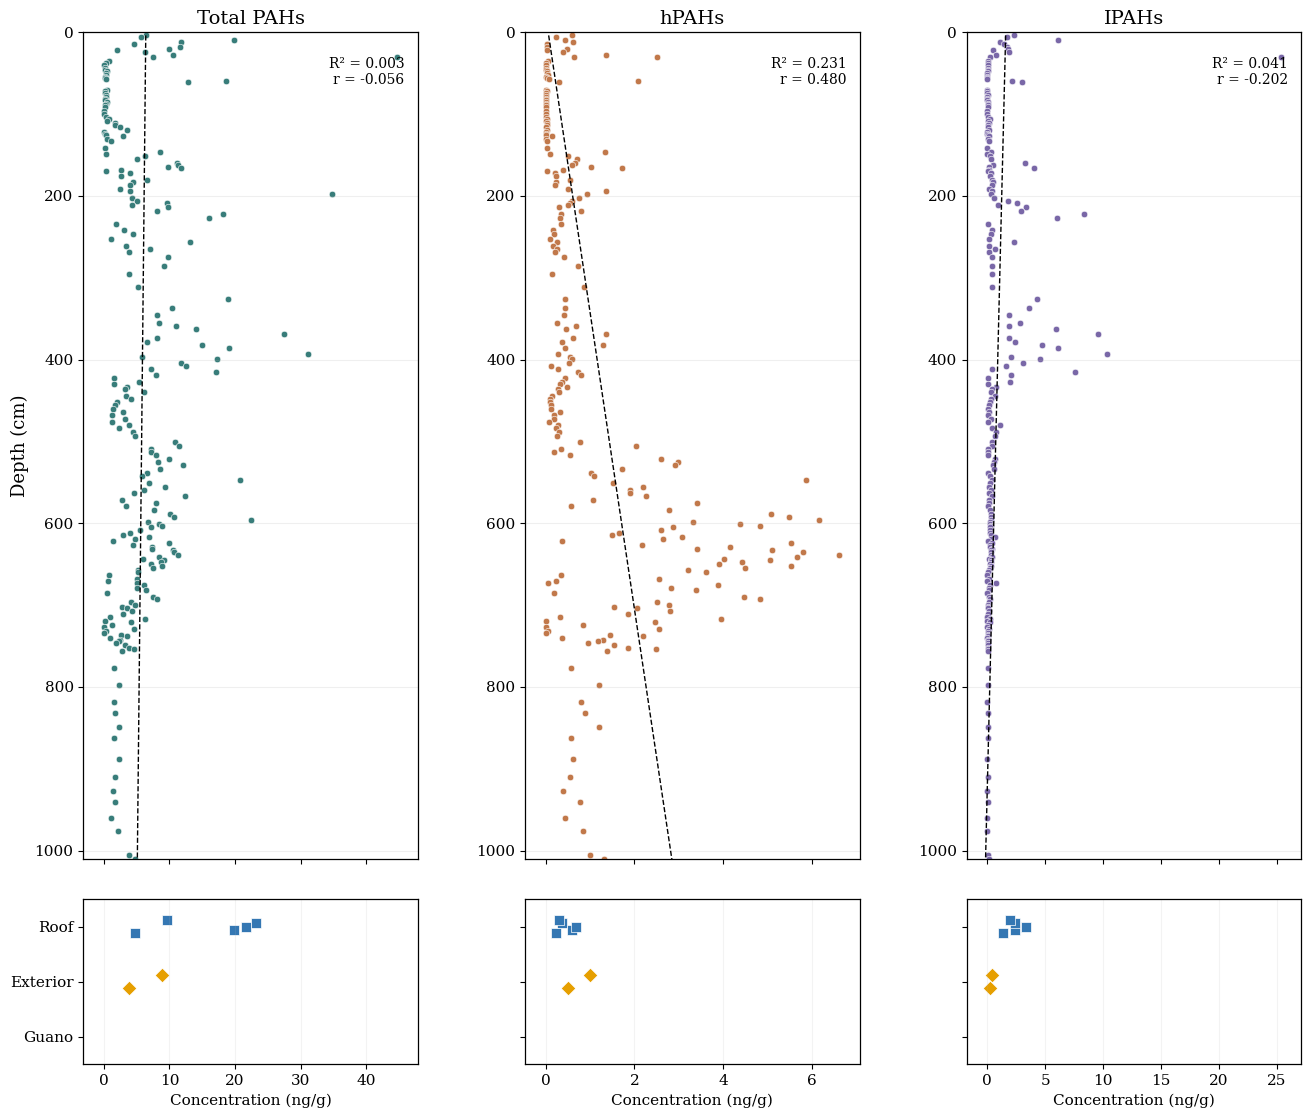

/tmp/ipykernel_902/287234547.py:462: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  correlations.to_excel(
/tmp/ipykernel_902/287234547.py:466: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  overall.to_excel(
/tmp/ipykernel_902/287234547.py:470: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  walls.to_excel(
/tmp/ipykernel_902/287234547.py:474: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  modern_stats.to_excel(
/tmp/ipykernel_902/287234547.py:478: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  extremes.to_excel(
/tmp/ipykernel_902/287234547.py

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PAH analysis completed successfully.


In [ ]:

# ============================================================
# AZYKH CAVE 1 — COMPLETE PAH ANALYSIS
# Including modern Roof, Exterior and Guano samples
# Total PAHs, hPAHs and IPAHs
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import linregress, spearmanr
from google.colab import files
import io
import re
import os
import zipfile

# ---------- SETTINGS ----------
OUT = "Azykh_PAH_Results"
os.makedirs(OUT, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.linewidth": 0.9,
    "pdf.fonttype": 42,
    "axes.unicode_minus": False
})

# ---------- 1. UPLOAD ----------
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_csv(
        io.BytesIO(uploaded[filename]),
        sep=None,
        engine="python",
        encoding="utf-8-sig"
    )

df.columns = df.columns.astype(str).str.strip()

# ---------- 2. MATCH COLUMNS ----------
def norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def find_col(name):
    matches = [
        c for c in df.columns
        if norm(c) == norm(name)
    ]
    if not matches:
        raise ValueError(
            f"Missing: {name}\n"
            f"Available: {df.columns.tolist()}"
        )
    return matches[0]

depth_col = find_col("Depth")
wall_col = find_col("Walls")

proxy_cols = {
    "Total PAHs": find_col("[PAHs](ng/g)"),
    "hPAHs": find_col("hPAHs(ng/g)"),
    "IPAHs": find_col("IPAHs(ng/g)")
}

print("\nMatched columns:")
print(proxy_cols)

# ---------- 3. NUMERIC CONVERSION ----------
def numeric(s):
    return pd.to_numeric(
        s.astype(str)
        .str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

df["Depth_cm"] = numeric(df[depth_col])

for proxy, col in proxy_cols.items():
    df[proxy] = numeric(df[col])

# ---------- 4. IDENTIFY MODERN SAMPLES ----------
label_cols = [depth_col, wall_col]

if "Sample" in df.columns:
    label_cols.append("Sample")

labels = (
    df[label_cols]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.lower()
)

df["Group"] = "Cave"

df.loc[labels.str.contains("roof"), "Group"] = "Roof"
df.loc[labels.str.contains("exterior"), "Group"] = "Exterior"
df.loc[
    labels.str.contains("guano|gauno", regex=True),
    "Group"
] = "Guano"

# ---------- 5. CLASSIFY WALLS ----------
def wall_number(value):
    s = str(value).strip().lower()
    s = re.sub(r"^wall\s*", "", s)
    s = re.sub(r"^w[-\s]*", "", s)

    roman = {
        "i": 1, "ii": 2, "iii": 3,
        "iv": 4, "v": 5, "vi": 6
    }

    if s in roman:
        return roman[s]

    try:
        n = int(float(s))
        return n if 1 <= n <= 6 else np.nan
    except (ValueError, TypeError):
        return np.nan

df["Wall_num"] = df[wall_col].apply(wall_number)

# ---------- 6. SPLIT DATA ----------
cave = df[
    (df["Group"] == "Cave") &
    df["Depth_cm"].between(0, 1010.5)
].copy()

modern = df[
    df["Group"].isin(["Roof", "Exterior", "Guano"])
].copy()

print("\nCave samples:", len(cave))
print("Modern samples:", len(modern))
print("\nModern groups:")
print(modern["Group"].value_counts())

# ---------- 7. SUMMARY FUNCTION ----------
def summarize(data, group, proxy):
    result = (
        data.dropna(subset=[proxy])
        .groupby(group)[proxy]
        .agg(
            n="count",
            Minimum="min",
            Maximum="max",
            Mean="mean",
            Median="median",
            SD="std"
        )
        .reset_index()
    )

    result["Range"] = (
        result["Maximum"] - result["Minimum"]
    )

    return result

# ---------- 8. STATISTICAL ANALYSIS ----------
reported_r2 = {
    "Total PAHs": 0.003,
    "hPAHs": 0.235,
    "IPAHs": 0.040
}

correlation_rows = []
overall_rows = []
wall_tables = []
modern_tables = []
extreme_tables = []

for proxy in proxy_cols:

    sub = cave.dropna(
        subset=["Depth_cm", proxy]
    )

    if len(sub) < 3:
        print(f"Insufficient data: {proxy}")
        continue

    reg = linregress(
        sub["Depth_cm"],
        sub[proxy]
    )

    rho, sp = spearmanr(
        sub["Depth_cm"],
        sub[proxy]
    )

    r2 = reg.rvalue ** 2

    correlation_rows.append({
        "Proxy": proxy,
        "n": len(sub),
        "Pearson_r": reg.rvalue,
        "R_squared": r2,
        "Pearson_p": reg.pvalue,
        "Spearman_rho": rho,
        "Spearman_p": sp,
        "Slope_per_cm": reg.slope,
        "Reported_R2": reported_r2[proxy],
        "R2_check": (
            "MATCH"
            if abs(r2 - reported_r2[proxy]) <= 0.0015
            else "MISMATCH"
        )
    })

    values = sub[proxy]

    overall_rows.append({
        "Proxy": proxy,
        "n": len(values),
        "Minimum": values.min(),
        "Maximum": values.max(),
        "Mean": values.mean(),
        "Median": values.median(),
        "SD": values.std(),
        "Range": values.max() - values.min()
    })

    wt = summarize(
        sub.dropna(subset=["Wall_num"]),
        "Wall_num", proxy
    )
    wt.insert(0, "Proxy", proxy)
    wall_tables.append(wt)

    mt = summarize(
        modern, "Group", proxy
    )
    mt.insert(0, "Proxy", proxy)
    modern_tables.append(mt)

    id_cols = [
        c for c in [
            "Serial", "Sample", "Depth_cm",
            wall_col, proxy
        ] if c in sub.columns
    ]

    high = sub.nlargest(5, proxy)[id_cols].copy()
    low = sub.nsmallest(5, proxy)[id_cols].copy()

    for table, kind in [(high, "Highest"), (low, "Lowest")]:
        table.insert(0, "Extreme", kind)
        table.insert(0, "Proxy", proxy)
        table.rename(
            columns={proxy: "Concentration_ng_g"},
            inplace=True
        )
        extreme_tables.append(table)

correlations = pd.DataFrame(correlation_rows)
overall = pd.DataFrame(overall_rows)
walls = pd.concat(wall_tables, ignore_index=True)
modern_stats = pd.concat(modern_tables, ignore_index=True)
extremes = pd.concat(extreme_tables, ignore_index=True)

# ---------- 9. PRINT TABLES ----------
def show(title, table):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)
    print(table.round(4).to_string(index=False))

show("1. CORRELATIONS WITH DEPTH", correlations)
show("2. OVERALL PAH STATISTICS (ng/g)", overall)
show("3. WALL-BY-WALL STATISTICS", walls)
show("4. MODERN REFERENCE STATISTICS", modern_stats)
show("5. HIGHEST AND LOWEST VALUES", extremes)

# ---------- 10. PLOT CAVE + MODERN ----------
fig = plt.figure(figsize=(14, 12))

gs = GridSpec(
    2, 3,
    height_ratios=[10, 2],
    hspace=0.08,
    wspace=0.32
)

colors = {
    "Total PAHs": "#387D7A",
    "hPAHs": "#C1784A",
    "IPAHs": "#7967A7"
}

modern_colors = {
    "Roof": "#3477B3",
    "Exterior": "#E69F00",
    "Guano": "#9A62AC"
}

modern_markers = {
    "Roof": "s",
    "Exterior": "D",
    "Guano": "^"
}

positions = {
    "Roof": 3,
    "Exterior": 2,
    "Guano": 1
}

for i, proxy in enumerate(proxy_cols):

    ax = fig.add_subplot(gs[0, i])
    ax_mod = fig.add_subplot(
        gs[1, i],
        sharex=ax
    )

    sub = cave.dropna(
        subset=["Depth_cm", proxy]
    )

    ax.scatter(
        sub[proxy],
        sub["Depth_cm"],
        s=22,
        color=colors[proxy],
        edgecolor="white",
        linewidth=0.4
    )

    if len(sub) >= 3:
        reg = linregress(
            sub["Depth_cm"],
            sub[proxy]
        )

        depths = np.linspace(
            sub["Depth_cm"].min(),
            sub["Depth_cm"].max(),
            400
        )

        ax.plot(
            reg.intercept + reg.slope * depths,
            depths,
            "--",
            color="black",
            linewidth=1
        )

        ax.text(
            0.96, 0.97,
            f"R² = {reg.rvalue**2:.3f}\n"
            f"r = {reg.rvalue:.3f}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=10
        )

    ax.set_ylim(1010.5, 0)
    ax.set_title(proxy, fontsize=14)
    ax.grid(axis="y", alpha=0.2)
    ax.tick_params(axis="x", labelbottom=False)

    if i == 0:
        ax.set_ylabel("Depth (cm)", fontsize=13)

    # Modern reference samples
    for group in ["Roof", "Exterior", "Guano"]:

        group_data = modern[
            (modern["Group"] == group) &
            modern[proxy].notna()
        ]

        if group_data.empty:
            continue

        offsets = (
            np.linspace(-0.12, 0.12, len(group_data))
            if len(group_data) > 1
            else np.array([0])
        )

        ax_mod.scatter(
            group_data[proxy],
            positions[group] + offsets,
            color=modern_colors[group],
            marker=modern_markers[group],
            s=55,
            edgecolor="white",
            linewidth=0.5
        )

    ax_mod.set_ylim(0.5, 3.5)
    ax_mod.set_yticks([1, 2, 3])

    if i == 0:
        ax_mod.set_yticklabels([
            "Guano", "Exterior", "Roof"
        ])
    else:
        ax_mod.set_yticklabels([])

    ax_mod.set_xlabel(
        "Concentration (ng/g)",
        fontsize=11
    )
    ax_mod.grid(axis="x", alpha=0.15)

    # Shared X-axis includes cave and modern samples
    combined = pd.concat([
        cave[proxy],
        modern[proxy]
    ]).dropna()

    if not combined.empty:
        xmin = min(0, combined.min())
        xmax = combined.max()
        padding = max((xmax - xmin) * 0.07, 0.1)
        ax.set_xlim(xmin - padding, xmax + padding)

fig.subplots_adjust(
    left=0.10,
    right=0.97,
    top=0.94,
    bottom=0.08
)

for ext in ["png", "pdf"]:
    fig.savefig(
        os.path.join(OUT, f"PAH_Cave_Modern.{ext}"),
        dpi=600,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)

# ---------- 11. EXPORT EXCEL ----------
output_excel = os.path.join(
    OUT,
    "Azykh_PAH_Full_Statistics.xlsx"
)

with pd.ExcelWriter(
    output_excel,
    engine="openpyxl"
) as writer:

    correlations.to_excel(
        writer, "Correlations", index=False
    )

    overall.to_excel(
        writer, "Overall", index=False
    )

    walls.to_excel(
        writer, "Wall Statistics", index=False
    )

    modern_stats.to_excel(
        writer, "Modern Statistics", index=False
    )

    extremes.to_excel(
        writer, "Extreme Values", index=False
    )

    cave.to_excel(
        writer, "Cave Data", index=False
    )

    modern.to_excel(
        writer, "Modern Data", index=False
    )

# ---------- 12. ZIP ALL OUTPUTS ----------
zip_name = "Azykh_PAH_Cave_Modern_Results.zip"

with zipfile.ZipFile(
    zip_name, "w", zipfile.ZIP_DEFLATED
) as z:

    for name in os.listdir(OUT):
        z.write(
            os.path.join(OUT, name),
            arcname=name
        )

files.download(zip_name)

print("\nPAH analysis completed successfully.")


Upload your PAH and hydrogen isotope CSV/Excel files.


Saving Biomarker data.csv to Biomarker data.csv

Uploaded datasets:

Biomarker data.csv: 168 rows
['Sample ID;Depth;δ H31 wax (‰);δ H29 wax (‰);CPI ;ACL;Norm 31;DMP(x);DMP(y);LMW/total;Ret/3-ring;[PAHs](ng/g);hPAHs  (ng/g);IPAHs(ng/g);Walls']

Check the isotope file headers and add the correct name to ALIASES['d2H_C31'] before rerunning.

Cave samples: 0

=== SPEARMAN CORRELATIONS ===


,Variable_1,Variable_2,N,Spearman_rho,p_value
0,DMP_x,Total_PAH,0,NaN,NaN
1,DMP_y,Total_PAH,0,NaN,NaN
2,DMP_x,hPAH,0,NaN,NaN
3,DMP_y,hPAH,0,NaN,NaN



=== DEPTH-ADJUSTED SPEARMAN CORRELATIONS ===


,Variable_1,Variable_2,N,Partial_rho,p_value
0,DMP_x,Total_PAH,0,NaN,NaN
1,DMP_y,Total_PAH,0,NaN,NaN
2,DMP_x,hPAH,0,NaN,NaN
3,DMP_y,hPAH,0,NaN,NaN



=== WALL-BASED CORRELATIONS ===


,Wall,Variable_1,Variable_2,N,Spearman_rho,p_value
0,Wall 6,DMP_x,Total_PAH,0,NaN,NaN
1,Wall 6,DMP_y,Total_PAH,0,NaN,NaN
2,Wall 6,DMP_x,hPAH,0,NaN,NaN
3,Wall 6,DMP_y,hPAH,0,NaN,NaN
4,Wall 5,DMP_x,Total_PAH,0,NaN,NaN
5,Wall 5,DMP_y,Total_PAH,0,NaN,NaN
6,Wall 5,DMP_x,hPAH,0,NaN,NaN
7,Wall 5,DMP_y,hPAH,0,NaN,NaN
8,Wall 4,DMP_x,Total_PAH,0,NaN,NaN
9,Wall 4,DMP_y,Total_PAH,0,NaN,NaN


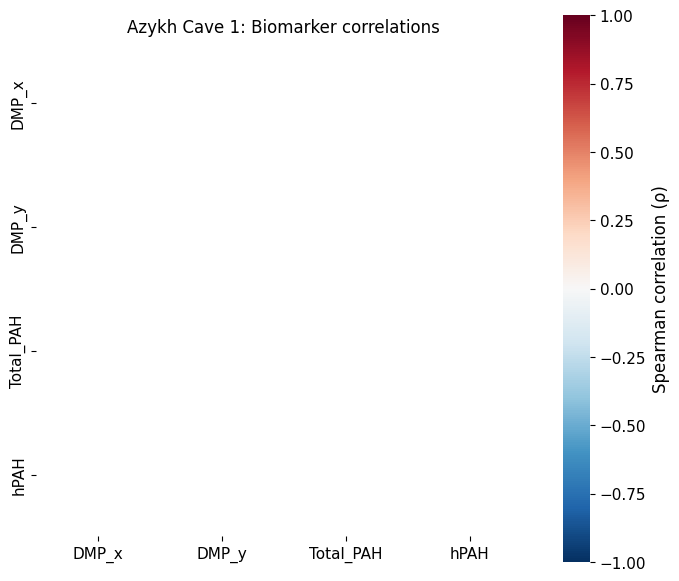

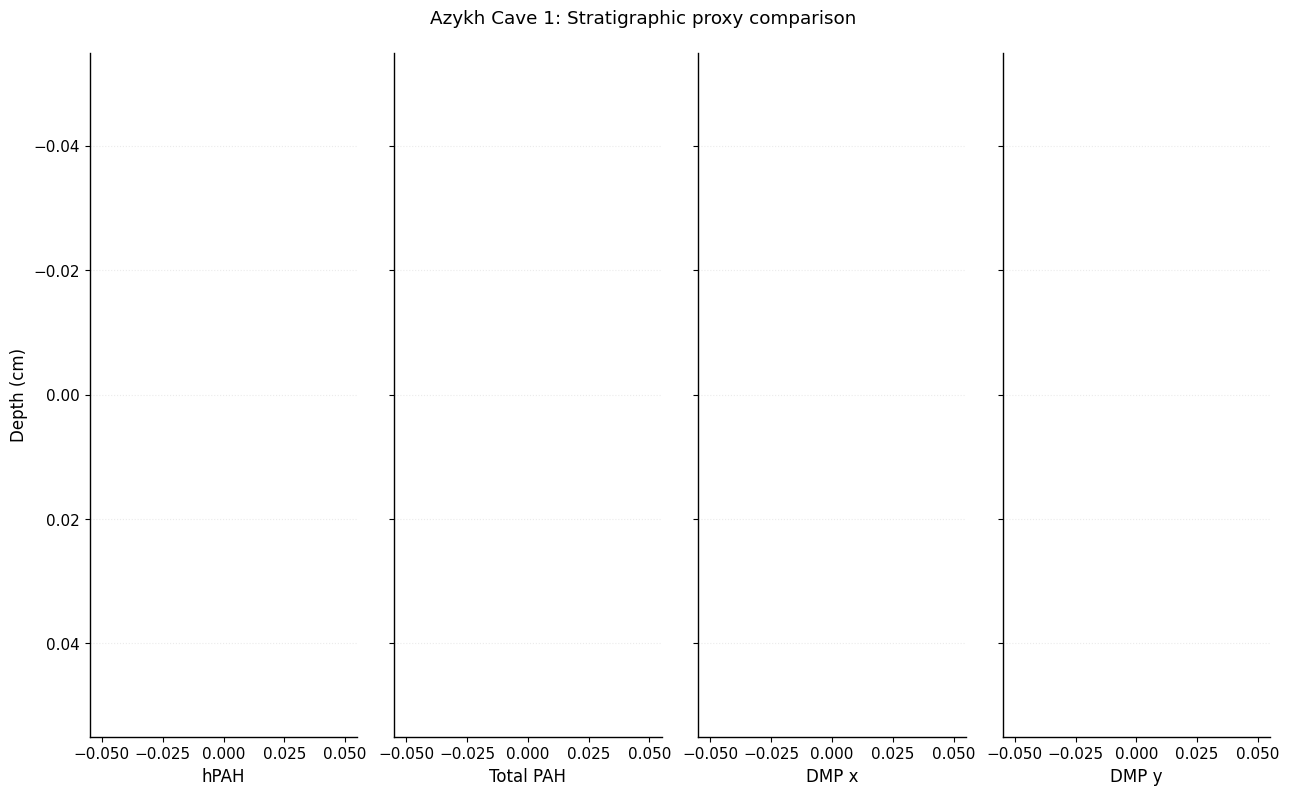


ANALYSIS COMPLETE
Files saved in: /content/Azykh_DMP_Analysis
Download ZIP: /content/Azykh_DMP_Analysis.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ==============================================================
# AZYKH CAVE 1 — DMP, PAH AND HYDROGEN ISOTOPE ANALYSIS
# Google Colab: Run this entire code in ONE cell
# ==============================================================

!pip -q install openpyxl scipy seaborn

import os, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr, kruskal, rankdata, pearsonr
from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# -------------------- SETTINGS --------------------
OUT = "/content/Azykh_DMP_Analysis"
os.makedirs(OUT, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "axes.linewidth": 1.0,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "savefig.dpi": 300
})

# -------------------- UPLOAD FILES --------------------
print("Upload your PAH and hydrogen isotope CSV/Excel files.")
uploaded = files.upload()

def load_file(name):
    if name.lower().endswith(".csv"):
        for encoding in ["utf-8-sig", "cp1252", "latin1"]:
            try:
                return pd.read_csv(name, encoding=encoding)
            except UnicodeDecodeError:
                continue
    if name.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(name)
    raise ValueError(f"Unsupported file: {name}")

tables = [(name, load_file(name)) for name in uploaded]

print("\nUploaded datasets:")
for name, df in tables:
    print(f"\n{name}: {len(df)} rows")
    print(list(df.columns))

# -------------------- COLUMN DETECTION --------------------
def norm(s):
    return re.sub(r"[^a-z0-9]+", "", str(s).lower())

def find_column(df, aliases, exclude=()):
    cols = list(df.columns)
    lookup = {norm(c): c for c in cols}

    for alias in aliases:
        if norm(alias) in lookup:
            return lookup[norm(alias)]

    for alias in aliases:
        for c in cols:
            if norm(alias) in norm(c) and not any(
                norm(x) in norm(c) for x in exclude
            ):
                return c
    return None

def numeric(series):
    return pd.to_numeric(
        series.astype(str).str.replace(",", ".", regex=False)
              .str.replace("‰", "", regex=False)
              .str.strip(),
        errors="coerce"
    )

def sample_key(s):
    # Removes fraction labels and common suffixes,
    # but preserves the actual sample number.
    x = str(s).strip().upper()
    x = re.sub(r"[\s_]+", "-", x)
    x = re.sub(r"-(F1|F2|F3)(?:$|-.*$)", "", x)
    return re.sub(r"[^A-Z0-9]", "", x)

ALIASES = {
    "Sample": ["Sample", "Sample ID", "Sample Name", "Sample_ID"],
    "Depth": ["Depth", "Depth (cm)", "Depth cm"],
    "Wall": ["Walls", "Wall"],
    "DMP_x": ["DMP(x)", "DMP-x", "DMP_x"],
    "DMP_y": ["DMP(y)", "DMP-y", "DMP_y"],
    "Total_PAH": [
        "[PAHs]\\(ng/g)", "PAHs(ng/g)", "PAH(ng/g)",
        "Total PAHs", "Sigma PAHs", "ΣPAHs"
    ],
    "hPAH": ["hPAHs (ng/g)", "hPAHs", "HPAHs", "High PAHs"],
    "d2H_C31": [
        "δ²H-C31", "δ2H-C31", "d2H_C31", "dD-C31",
        "C31 δ Final", "C31 d2H", "C31 dD"
    ]
}

def standardize(df):
    result = pd.DataFrame(index=df.index)
    for field, aliases in ALIASES.items():
        col = find_column(df, aliases)
        if col is not None:
            result[field] = df[col]

    if "Sample" in result:
        result["Sample_key"] = result["Sample"].map(sample_key)

    for field in ["Depth", "DMP_x", "DMP_y", "Total_PAH",
                  "hPAH", "d2H_C31"]:
        if field in result:
            result[field] = numeric(result[field])

    if "Wall" in result:
        result["Wall"] = (
            result["Wall"].astype(str)
            .str.extract(r"(?i)(?:wall|w)?\s*[-_ ]*([1-6])")[0]
            .map(lambda x: "Wall " + x if pd.notna(x) else np.nan)
        )

    return result

standard = [(name, standardize(df)) for name, df in tables]

# Identify the dataset containing DMP values.
pah_candidates = [
    (name, df) for name, df in standard
    if {"DMP_x", "DMP_y"}.issubset(df.columns)
]

if not pah_candidates:
    raise ValueError(
        "Could not find DMP(x) and DMP(y). "
        "Check your uploaded PAH column names."
    )

pah_name, main = max(pah_candidates, key=lambda x: len(x[1]))
main = main.copy()

if "Sample_key" not in main:
    raise ValueError("PAH dataset must contain a Sample ID column.")

# -------------------- ISOTOPE DATA --------------------
# Automatically merge if a recognizable δ²H-C31 column exists.
iso_candidates = [
    (name, df) for name, df in standard
    if name != pah_name and "d2H_C31" in df.columns
]

if "d2H_C31" not in main and iso_candidates:
    iso_name, iso = iso_candidates[0]
    iso = iso[["Sample_key", "d2H_C31"]].copy()

    # Avoid multiplying rows from duplicate IDs.
    duplicates = iso["Sample_key"].duplicated(keep=False)
    if duplicates.any():
        print("Warning: duplicate isotope sample IDs detected.")
        print("Using the median for duplicate IDs.")
        iso = iso.groupby("Sample_key", as_index=False).median()

    main = main.merge(
        iso, on="Sample_key", how="left", validate="many_to_one"
    )
    print(f"\nIsotope dataset matched: {iso_name}")

elif "d2H_C31" not in main:
    print(
        "\nWARNING: δ²H-C31 column not automatically detected.\n"
        "Check the isotope file headers and add the correct name "
        "to ALIASES['d2H_C31'] before rerunning."
    )

# Cave samples only: numeric depths, no Roof/Exterior/Guano.
if "Depth" not in main:
    raise ValueError("A numeric Depth column is required.")

main = main.loc[main["Depth"].notna()].copy()
main = main.sort_values("Depth").reset_index(drop=True)

if "Wall" not in main:
    main["Wall"] = np.nan

print("\nCave samples:", len(main))
if "d2H_C31" in main:
    print("Matched δ²H-C31:", main["d2H_C31"].notna().sum())

main.to_csv(f"{OUT}/01_Matched_Data.csv", index=False)

# -------------------- CORRELATION TESTS --------------------
variables = [
    c for c in ["DMP_x", "DMP_y", "Total_PAH",
                "hPAH", "d2H_C31"]
    if c in main.columns
]

def correlation(df, a, b):
    sub = df[[a, b]].dropna()
    n = len(sub)

    if n < 4 or sub[a].nunique() < 2 or sub[b].nunique() < 2:
        return {"N": n, "Spearman_rho": np.nan, "p_value": np.nan}

    rho, p = spearmanr(sub[a], sub[b])
    return {"N": n, "Spearman_rho": rho, "p_value": p}

pairs = [
    ("DMP_x", "d2H_C31"),
    ("DMP_y", "d2H_C31"),
    ("DMP_x", "Total_PAH"),
    ("DMP_y", "Total_PAH"),
    ("DMP_x", "hPAH"),
    ("DMP_y", "hPAH"),
    ("hPAH", "d2H_C31"),
    ("Total_PAH", "d2H_C31")
]

results = []
for a, b in pairs:
    if a in main and b in main:
        results.append({"Variable_1": a, "Variable_2": b,
                        **correlation(main, a, b)})

corr_df = pd.DataFrame(results)
corr_df.to_csv(f"{OUT}/02_Spearman_Correlations.csv", index=False)

print("\n=== SPEARMAN CORRELATIONS ===")
display(corr_df.round(4))

# -------------------- DEPTH-ADJUSTED CORRELATIONS --------------------
# Partial Spearman: rank-transform each variable and depth,
# regress ranks against ranked depth, correlate residuals.
# Approximate p-values are computed using a t distribution.
from scipy.stats import t as student_t

def partial_spearman(df, a, b):
    sub = df[[a, b, "Depth"]].dropna()
    n = len(sub)

    if n < 5 or any(sub[c].nunique() < 2 for c in [a, b, "Depth"]):
        return {"N": n, "Partial_rho": np.nan, "p_value": np.nan}

    x = rankdata(sub[a])
    y = rankdata(sub[b])
    z = rankdata(sub["Depth"])

    X = np.column_stack([np.ones(n), z])
    rx = x - X @ np.linalg.lstsq(X, x, rcond=None)[0]
    ry = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]

    if np.std(rx) == 0 or np.std(ry) == 0:
        return {"N": n, "Partial_rho": np.nan, "p_value": np.nan}

    r = np.corrcoef(rx, ry)[0, 1]
    dfree = n - 3
    tval = r * np.sqrt(dfree / max(1e-12, 1-r*r))
    p = 2 * student_t.sf(abs(tval), dfree)

    return {"N": n, "Partial_rho": r, "p_value": p}

partial_results = []
for a, b in pairs:
    if a in main and b in main:
        partial_results.append({
            "Variable_1": a, "Variable_2": b,
            **partial_spearman(main, a, b)
        })

partial_df = pd.DataFrame(partial_results)
partial_df.to_csv(
    f"{OUT}/03_Depth_Adjusted_Correlations.csv", index=False
)

print("\n=== DEPTH-ADJUSTED SPEARMAN CORRELATIONS ===")
display(partial_df.round(4))

# -------------------- WALL-BASED CORRELATIONS --------------------
wall_results = []

for wall in [f"Wall {i}" for i in range(6, 0, -1)]:
    subset = main.loc[main["Wall"] == wall]

    for a, b in pairs:
        if a in subset and b in subset:
            wall_results.append({
                "Wall": wall, "Variable_1": a, "Variable_2": b,
                **correlation(subset, a, b)
            })

wall_df = pd.DataFrame(wall_results)
wall_df.to_csv(f"{OUT}/04_Wall_Correlations.csv", index=False)

print("\n=== WALL-BASED CORRELATIONS ===")
display(wall_df.round(3))

# -------------------- PLOT 1: CORRELATION HEATMAP --------------------
if len(variables) >= 2:
    matrix = main[variables].corr(method="spearman")

    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(
        matrix, annot=True, fmt=".2f", cmap="RdBu_r",
        vmin=-1, vmax=1, center=0, square=True,
        linewidths=0.5, ax=ax,
        cbar_kws={"label": "Spearman correlation (ρ)"}
    )
    ax.set_title("Azykh Cave 1: Biomarker correlations")
    fig.tight_layout()
    fig.savefig(f"{OUT}/Fig1_Correlation_Heatmap.png", dpi=400)
    fig.savefig(f"{OUT}/Fig1_Correlation_Heatmap.pdf")
    plt.show()

# -------------------- PLOT 2: DMP SCATTERPLOTS --------------------
def dmp_plot(color_col, filename, cmap):
    if color_col not in main:
        return

    sub = main[["DMP_x", "DMP_y", color_col]].dropna()
    if sub.empty:
        return

    fig, ax = plt.subplots(figsize=(7, 5.8))
    sc = ax.scatter(
        sub["DMP_x"], sub["DMP_y"],
        c=sub[color_col], cmap=cmap,
        s=42, edgecolor="black", linewidth=0.25,
        alpha=0.85
    )

    cb = fig.colorbar(sc, ax=ax, pad=0.02)
    cb.set_label(color_col.replace("_", " "))

    ax.set_xlabel("DMP-x")
    ax.set_ylabel("DMP-y")
    ax.set_title(f"DMP ratios coloured by {color_col}")
    ax.spines[["top", "right"]].set_visible(False)

    fig.tight_layout()
    fig.savefig(f"{OUT}/{filename}.png", dpi=400)
    fig.savefig(f"{OUT}/{filename}.pdf")
    plt.show()

dmp_plot("Total_PAH", "Fig2_DMP_Total_PAH", "viridis")
dmp_plot("hPAH", "Fig3_DMP_hPAH", "plasma")
dmp_plot("d2H_C31", "Fig4_DMP_d2H_C31", "coolwarm")

# -------------------- PLOT 3: STRATIGRAPHIC PROFILES --------------------
profile_vars = [
    c for c in ["d2H_C31", "hPAH", "Total_PAH", "DMP_x", "DMP_y"]
    if c in main
]

if profile_vars:
    fig, axes = plt.subplots(
        1, len(profile_vars),
        figsize=(3.0 * len(profile_vars) + 1, 8),
        sharey=True
    )

    axes = np.atleast_1d(axes)

    for ax, variable in zip(axes, profile_vars):
        sub = main[["Depth", variable]].dropna().sort_values("Depth")
        ax.plot(
            sub[variable], sub["Depth"],
            "-", linewidth=0.65, alpha=0.55
        )
        ax.scatter(
            sub[variable], sub["Depth"],
            s=12, alpha=0.8
        )
        ax.set_xlabel(variable.replace("_", " "))
        ax.grid(axis="y", linestyle=":", alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)

    axes[0].set_ylabel("Depth (cm)")
    axes[0].invert_yaxis()

    fig.suptitle("Azykh Cave 1: Stratigraphic proxy comparison", y=0.99)
    fig.tight_layout()
    fig.savefig(f"{OUT}/Fig5_Stratigraphic_Profiles.png", dpi=400)
    fig.savefig(f"{OUT}/Fig5_Stratigraphic_Profiles.pdf")
    plt.show()

# -------------------- PLOT 4: WALL COMPARISON --------------------
if main["Wall"].notna().any():
    for variable in ["DMP_x", "DMP_y", "hPAH", "d2H_C31"]:
        if variable not in main:
            continue

        fig, ax = plt.subplots(figsize=(8, 4.8))
        sns.boxplot(
            data=main, x="Wall", y=variable,
            order=[f"Wall {i}" for i in range(6, 0, -1)],
            color="lightgray", showfliers=False, ax=ax
        )
        sns.stripplot(
            data=main, x="Wall", y=variable,
            order=[f"Wall {i}" for i in range(6, 0, -1)],
            color="black", size=3, alpha=0.45, ax=ax
        )
        ax.set_xlabel("")
        ax.set_ylabel(variable)
        ax.spines[["top", "right"]].set_visible(False)
        fig.tight_layout()

        fig.savefig(f"{OUT}/Fig_Walls_{variable}.png", dpi=400)
        fig.savefig(f"{OUT}/Fig_Walls_{variable}.pdf")
        plt.show()

# -------------------- EXPORT --------------------
zip_path = "/content/Azykh_DMP_Analysis.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in os.listdir(OUT):
        z.write(os.path.join(OUT, filename), arcname=filename)

print("\nANALYSIS COMPLETE")
print("Files saved in:", OUT)
print("Download ZIP:", zip_path)

files.download(zip_path)


In [ ]:

# ==============================================================
# AZYKH CAVE 1 — DMP, PAH AND HYDROGEN ISOTOPE ANALYSIS
# Google Colab: Run this entire code in ONE cell
# ==============================================================

!pip -q install openpyxl scipy seaborn

import os, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr, kruskal, rankdata, pearsonr
from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# -------------------- SETTINGS --------------------
OUT = "/content/Azykh_DMP_Analysis"
os.makedirs(OUT, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "axes.linewidth": 1.0,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "savefig.dpi": 300
})

# -------------------- UPLOAD FILES --------------------
print("Upload your PAH and hydrogen isotope CSV/Excel files.")
uploaded = files.upload()

def load_file(name):
    if name.lower().endswith(".csv"):
        for encoding in ["utf-8-sig", "cp1252", "latin1"]:
            try:
                return pd.read_csv(name, encoding=encoding)
            except UnicodeDecodeError:
                continue
    if name.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(name)
    raise ValueError(f"Unsupported file: {name}")

tables = [(name, load_file(name)) for name in uploaded]

print("\nUploaded datasets:")
for name, df in tables:
    print(f"\n{name}: {len(df)} rows")
    print(list(df.columns))

# -------------------- COLUMN DETECTION --------------------
def norm(s):
    return re.sub(r"[^a-z0-9]+", "", str(s).lower())

def find_column(df, aliases, exclude=()):
    cols = list(df.columns)
    lookup = {norm(c): c for c in cols}

    for alias in aliases:
        if norm(alias) in lookup:
            return lookup[norm(alias)]

    for alias in aliases:
        for c in cols:
            if norm(alias) in norm(c) and not any(
                norm(x) in norm(c) for x in exclude
            ):
                return c
    return None

def numeric(series):
    return pd.to_numeric(
        series.astype(str).str.replace(",", ".", regex=False)
              .str.replace("‰", "", regex=False)
              .str.strip(),
        errors="coerce"
    )

def sample_key(s):
    # Removes fraction labels and common suffixes,
    # but preserves the actual sample number.
    x = str(s).strip().upper()
    x = re.sub(r"[\s_]+", "-", x)
    x = re.sub(r"-(F1|F2|F3)(?:$|-.*$)", "", x)
    return re.sub(r"[^A-Z0-9]", "", x)

ALIASES = {
    "Sample": ["Sample", "Sample ID", "Sample Name", "Sample_ID"],
    "Depth": ["Depth", "Depth (cm)", "Depth cm"],
    "Wall": ["Walls", "Wall"],
    "DMP_x": ["DMP(x)", "DMP-x", "DMP_x"],
    "DMP_y": ["DMP(y)", "DMP-y", "DMP_y"],
    "Total_PAH": [
        "[PAHs]\\(ng/g)", "PAHs(ng/g)", "PAH(ng/g)",
        "Total PAHs", "Sigma PAHs", "ΣPAHs"
    ],
    "hPAH": ["hPAHs (ng/g)", "hPAHs", "HPAHs", "High PAHs"],
    "d2H_C31": [
        "δ²H-C31", "δ2H-C31", "d2H_C31", "dD-C31",
        "C31 δ Final", "C31 d2H", "C31 dD"
    ]
}

def standardize(df):
    result = pd.DataFrame(index=df.index)
    for field, aliases in ALIASES.items():
        col = find_column(df, aliases)
        if col is not None:
            result[field] = df[col]

    if "Sample" in result:
        result["Sample_key"] = result["Sample"].map(sample_key)

    for field in ["Depth", "DMP_x", "DMP_y", "Total_PAH",
                  "hPAH", "d2H_C31"]:
        if field in result:
            result[field] = numeric(result[field])

    if "Wall" in result:
        result["Wall"] = (
            result["Wall"].astype(str)
            .str.extract(r"(?i)(?:wall|w)?\s*[-_ ]*([1-6])")[0]
            .map(lambda x: "Wall " + x if pd.notna(x) else np.nan)
        )

    return result

standard = [(name, standardize(df)) for name, df in tables]

# Identify the dataset containing DMP values.
pah_candidates = [
    (name, df) for name, df in standard
    if {"DMP_x", "DMP_y"}.issubset(df.columns)
]

if not pah_candidates:
    raise ValueError(
        "Could not find DMP(x) and DMP(y). "
        "Check your uploaded PAH column names."
    )

pah_name, main = max(pah_candidates, key=lambda x: len(x[1]))
main = main.copy()

if "Sample_key" not in main:
    raise ValueError("PAH dataset must contain a Sample ID column.")

# -------------------- ISOTOPE DATA --------------------
# Automatically merge if a recognizable δ²H-C31 column exists.
iso_candidates = [
    (name, df) for name, df in standard
    if name != pah_name and "d2H_C31" in df.columns
]

if "d2H_C31" not in main and iso_candidates:
    iso_name, iso = iso_candidates[0]
    iso = iso[["Sample_key", "d2H_C31"]].copy()

    # Avoid multiplying rows from duplicate IDs.
    duplicates = iso["Sample_key"].duplicated(keep=False)
    if duplicates.any():
        print("Warning: duplicate isotope sample IDs detected.")
        print("Using the median for duplicate IDs.")
        iso = iso.groupby("Sample_key", as_index=False).median()

    main = main.merge(
        iso, on="Sample_key", how="left", validate="many_to_one"
    )
    print(f"\nIsotope dataset matched: {iso_name}")

elif "d2H_C31" not in main:
    print(
        "\nWARNING: δ²H-C31 column not automatically detected.\n"
        "Check the isotope file headers and add the correct name "
        "to ALIASES['d2H_C31'] before rerunning."
    )

# Cave samples only: numeric depths, no Roof/Exterior/Guano.
if "Depth" not in main:
    raise ValueError("A numeric Depth column is required.")

main = main.loc[main["Depth"].notna()].copy()
main = main.sort_values("Depth").reset_index(drop=True)

if "Wall" not in main:
    main["Wall"] = np.nan

print("\nCave samples:", len(main))
if "d2H_C31" in main:
    print("Matched δ²H-C31:", main["d2H_C31"].notna().sum())

main.to_csv(f"{OUT}/01_Matched_Data.csv", index=False)

# -------------------- CORRELATION TESTS --------------------
variables = [
    c for c in ["DMP_x", "DMP_y", "Total_PAH",
                "hPAH", "d2H_C31"]
    if c in main.columns
]

def correlation(df, a, b):
    sub = df[[a, b]].dropna()
    n = len(sub)

    if n < 4 or sub[a].nunique() < 2 or sub[b].nunique() < 2:
        return {"N": n, "Spearman_rho": np.nan, "p_value": np.nan}

    rho, p = spearmanr(sub[a], sub[b])
    return {"N": n, "Spearman_rho": rho, "p_value": p}

pairs = [
    ("DMP_x", "d2H_C31"),
    ("DMP_y", "d2H_C31"),
    ("DMP_x", "Total_PAH"),
    ("DMP_y", "Total_PAH"),
    ("DMP_x", "hPAH"),
    ("DMP_y", "hPAH"),
    ("hPAH", "d2H_C31"),
    ("Total_PAH", "d2H_C31")
]

results = []
for a, b in pairs:
    if a in main and b in main:
        results.append({"Variable_1": a, "Variable_2": b,
                        **correlation(main, a, b)})

corr_df = pd.DataFrame(results)
corr_df.to_csv(f"{OUT}/02_Spearman_Correlations.csv", index=False)

print("\n=== SPEARMAN CORRELATIONS ===")
display(corr_df.round(4))

# -------------------- DEPTH-ADJUSTED CORRELATIONS --------------------
# Partial Spearman: rank-transform each variable and depth,
# regress ranks against ranked depth, correlate residuals.
# Approximate p-values are computed using a t distribution.
from scipy.stats import t as student_t

def partial_spearman(df, a, b):
    sub = df[[a, b, "Depth"]].dropna()
    n = len(sub)

    if n < 5 or any(sub[c].nunique() < 2 for c in [a, b, "Depth"]):
        return {"N": n, "Partial_rho": np.nan, "p_value": np.nan}

    x = rankdata(sub[a])
    y = rankdata(sub[b])
    z = rankdata(sub["Depth"])

    X = np.column_stack([np.ones(n), z])
    rx = x - X @ np.linalg.lstsq(X, x, rcond=None)[0]
    ry = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]

    if np.std(rx) == 0 or np.std(ry) == 0:
        return {"N": n, "Partial_rho": np.nan, "p_value": np.nan}

    r = np.corrcoef(rx, ry)[0, 1]
    dfree = n - 3
    tval = r * np.sqrt(dfree / max(1e-12, 1-r*r))
    p = 2 * student_t.sf(abs(tval), dfree)

    return {"N": n, "Partial_rho": r, "p_value": p}

partial_results = []
for a, b in pairs:
    if a in main and b in main:
        partial_results.append({
            "Variable_1": a, "Variable_2": b,
            **partial_spearman(main, a, b)
        })

partial_df = pd.DataFrame(partial_results)
partial_df.to_csv(
    f"{OUT}/03_Depth_Adjusted_Correlations.csv", index=False
)

print("\n=== DEPTH-ADJUSTED SPEARMAN CORRELATIONS ===")
display(partial_df.round(4))

# -------------------- WALL-BASED CORRELATIONS --------------------
wall_results = []

for wall in [f"Wall {i}" for i in range(6, 0, -1)]:
    subset = main.loc[main["Wall"] == wall]

    for a, b in pairs:
        if a in subset and b in subset:
            wall_results.append({
                "Wall": wall, "Variable_1": a, "Variable_2": b,
                **correlation(subset, a, b)
            })

wall_df = pd.DataFrame(wall_results)
wall_df.to_csv(f"{OUT}/04_Wall_Correlations.csv", index=False)

print("\n=== WALL-BASED CORRELATIONS ===")
display(wall_df.round(3))

# -------------------- PLOT 1: CORRELATION HEATMAP --------------------
if len(variables) >= 2:
    matrix = main[variables].corr(method="spearman")

    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(
        matrix, annot=True, fmt=".2f", cmap="RdBu_r",
        vmin=-1, vmax=1, center=0, square=True,
        linewidths=0.5, ax=ax,
        cbar_kws={"label": "Spearman correlation (ρ)"}
    )
    ax.set_title("Azykh Cave 1: Biomarker correlations")
    fig.tight_layout()
    fig.savefig(f"{OUT}/Fig1_Correlation_Heatmap.png", dpi=400)
    fig.savefig(f"{OUT}/Fig1_Correlation_Heatmap.pdf")
    plt.show()

# -------------------- PLOT 2: DMP SCATTERPLOTS --------------------
def dmp_plot(color_col, filename, cmap):
    if color_col not in main:
        return

    sub = main[["DMP_x", "DMP_y", color_col]].dropna()
    if sub.empty:
        return

    fig, ax = plt.subplots(figsize=(7, 5.8))
    sc = ax.scatter(
        sub["DMP_x"], sub["DMP_y"],
        c=sub[color_col], cmap=cmap,
        s=42, edgecolor="black", linewidth=0.25,
        alpha=0.85
    )

    cb = fig.colorbar(sc, ax=ax, pad=0.02)
    cb.set_label(color_col.replace("_", " "))

    ax.set_xlabel("DMP-x")
    ax.set_ylabel("DMP-y")
    ax.set_title(f"DMP ratios coloured by {color_col}")
    ax.spines[["top", "right"]].set_visible(False)

    fig.tight_layout()
    fig.savefig(f"{OUT}/{filename}.png", dpi=400)
    fig.savefig(f"{OUT}/{filename}.pdf")
    plt.show()

dmp_plot("Total_PAH", "Fig2_DMP_Total_PAH", "viridis")
dmp_plot("hPAH", "Fig3_DMP_hPAH", "plasma")
dmp_plot("d2H_C31", "Fig4_DMP_d2H_C31", "coolwarm")

# -------------------- PLOT 3: STRATIGRAPHIC PROFILES --------------------
profile_vars = [
    c for c in ["d2H_C31", "hPAH", "Total_PAH", "DMP_x", "DMP_y"]
    if c in main
]

if profile_vars:
    fig, axes = plt.subplots(
        1, len(profile_vars),
        figsize=(3.0 * len(profile_vars) + 1, 8),
        sharey=True
    )

    axes = np.atleast_1d(axes)

    for ax, variable in zip(axes, profile_vars):
        sub = main[["Depth", variable]].dropna().sort_values("Depth")
        ax.plot(
            sub[variable], sub["Depth"],
            "-", linewidth=0.65, alpha=0.55
        )
        ax.scatter(
            sub[variable], sub["Depth"],
            s=12, alpha=0.8
        )
        ax.set_xlabel(variable.replace("_", " "))
        ax.grid(axis="y", linestyle=":", alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)

    axes[0].set_ylabel("Depth (cm)")
    axes[0].invert_yaxis()

    fig.suptitle("Azykh Cave 1: Stratigraphic proxy comparison", y=0.99)
    fig.tight_layout()
    fig.savefig(f"{OUT}/Fig5_Stratigraphic_Profiles.png", dpi=400)
    fig.savefig(f"{OUT}/Fig5_Stratigraphic_Profiles.pdf")
    plt.show()

# -------------------- PLOT 4: WALL COMPARISON --------------------
if main["Wall"].notna().any():
    for variable in ["DMP_x", "DMP_y", "hPAH", "d2H_C31"]:
        if variable not in main:
            continue

        fig, ax = plt.subplots(figsize=(8, 4.8))
        sns.boxplot(
            data=main, x="Wall", y=variable,
            order=[f"Wall {i}" for i in range(6, 0, -1)],
            color="lightgray", showfliers=False, ax=ax
        )
        sns.stripplot(
            data=main, x="Wall", y=variable,
            order=[f"Wall {i}" for i in range(6, 0, -1)],
            color="black", size=3, alpha=0.45, ax=ax
        )
        ax.set_xlabel("")
        ax.set_ylabel(variable)
        ax.spines[["top", "right"]].set_visible(False)
        fig.tight_layout()

        fig.savefig(f"{OUT}/Fig_Walls_{variable}.png", dpi=400)
        fig.savefig(f"{OUT}/Fig_Walls_{variable}.pdf")
        plt.show()

# -------------------- EXPORT --------------------
zip_path = "/content/Azykh_DMP_Analysis.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in os.listdir(OUT):
        z.write(os.path.join(OUT, filename), arcname=filename)

print("\nANALYSIS COMPLETE")
print("Files saved in:", OUT)
print("Download ZIP:", zip_path)

files.download(zip_path)


Upload your PAH and hydrogen isotope CSV/Excel files.


Saving Multiproxies data,,,.csv to Multiproxies data,,,.csv


ParserError: Error tokenizing data. C error: Expected 10 fields in line 17, saw 11


In [ ]:

import pandas as pd
import csv

def load_file(name):
    if name.lower().endswith(".csv"):
        for encoding in ["utf-8-sig", "cp1252", "latin1"]:
            try:
                # First attempt: standard CSV
                return pd.read_csv(
                    name,
                    encoding=encoding,
                    sep=None,
                    engine="python"
                )
            except (UnicodeDecodeError, pd.errors.ParserError):
                continue

        # Fallback: skip malformed rows and report warnings
        print(f"WARNING: Some malformed rows in {name} may be skipped.")

        return pd.read_csv(
            name,
            encoding="latin1",
            sep=",",
            engine="python",
            on_bad_lines="warn"
        )

    elif name.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(name)

    else:
        raise ValueError(f"Unsupported file: {name}")


In [ ]:
tables = [(name, load_file(name)) for name in uploaded]

In [ ]:

# ================================================================
# AZYKH CAVE 1
# DMP RATIOS, PAHs AND LEAF-WAX HYDROGEN ISOTOPES
# COMPLETE ONE-CELL GOOGLE COLAB ANALYSIS
# ================================================================

!pip -q install openpyxl scipy seaborn

import os
import re
import csv
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr, rankdata, t as student_t
from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# ================================================================
# 1. SETTINGS
# ================================================================

OUT = "/content/Azykh_DMP_Analysis"
os.makedirs(OUT, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "axes.linewidth": 1,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "savefig.dpi": 400,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

WALL_ORDER = [f"Wall {i}" for i in range(6, 0, -1)]

# ================================================================
# 2. UPLOAD CSV OR EXCEL FILES
# ================================================================

print("UPLOAD YOUR PAH AND HYDROGEN ISOTOPE FILES")
print("Supported formats: CSV, XLSX, XLS")
print("Upload both files together.\n")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No files uploaded.")

# ================================================================
# 3. ROBUST CSV LOADER — NO SILENTLY SKIPPED ROWS
# ================================================================

def load_csv_safely(filename):

    raw = None
    used_encoding = None

    for enc in ["utf-8-sig", "cp1252", "latin1"]:
        try:
            with open(filename, "r", encoding=enc) as f:
                raw = f.read()
            used_encoding = enc
            break
        except UnicodeDecodeError:
            continue

    if raw is None:
        raise ValueError(f"Cannot decode {filename}")

    # Try common delimiters and quoting conventions.
    attempts = [
        {"sep": ",", "quotechar": '"'},
        {"sep": ";", "quotechar": '"'},
        {"sep": "\t", "quotechar": '"'},
        {"sep": "|", "quotechar": '"'}
    ]

    candidates = []

    for opt in attempts:
        try:
            df = pd.read_csv(
                filename,
                encoding=used_encoding,
                sep=opt["sep"],
                quotechar=opt["quotechar"],
                engine="python",
                on_bad_lines="error"
            )

            if df.shape[1] > 1:
                candidates.append((df.shape[1], df, opt))

        except (pd.errors.ParserError, ValueError, csv.Error):
            continue

    if candidates:
        # Prefer the successful parse with the most columns.
        candidates.sort(key=lambda x: x[0], reverse=True)
        _, df, opt = candidates[0]

        print(f"\nLoaded: {filename}")
        print(f"Delimiter: {repr(opt['sep'])}")
        print(f"Rows: {len(df)} | Columns: {len(df.columns)}")

        return df

    print("\n" + "=" * 65)
    print("CSV FORMATTING ERROR")
    print("File:", filename)
    print("=" * 65)

    lines = raw.splitlines()

    for i, line in enumerate(lines):
        if 12 <= i <= 20:
            print(f"Line {i+1}: {line[:350]}")

    raise ValueError(
        f"\nUnable to parse {filename} without potentially losing data. "
        "Please correct the malformed CSV row shown above, "
        "or open the file in Excel and save it as XLSX, then rerun."
    )

def load_file(filename):

    if filename.lower().endswith(".csv"):
        return load_csv_safely(filename)

    if filename.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(filename)

    raise ValueError(f"Unsupported format: {filename}")

tables = []

for filename in uploaded:
    df = load_file(filename)
    tables.append((filename, df))

    print(f"\nFILE: {filename}")
    print("Columns:")
    print(list(df.columns))

# ================================================================
# 4. STANDARDIZE COLUMN NAMES
# ================================================================

def normalize(text):
    return re.sub(r"[^a-z0-9]", "", str(text).lower())

def find_col(df, aliases):

    lookup = {normalize(c): c for c in df.columns}

    for alias in aliases:
        if normalize(alias) in lookup:
            return lookup[normalize(alias)]

    for alias in aliases:
        matches = [
            c for c in df.columns
            if normalize(alias) in normalize(c)
        ]

        if len(matches) == 1:
            return matches[0]

    return None

ALIASES = {

    "Sample": [
        "Sample", "Sample ID", "Sample_ID",
        "Sample Name", "Sample Number"
    ],

    "Depth": [
        "Depth", "Depth (cm)", "Depth cm"
    ],

    "Wall": [
        "Walls", "Wall"
    ],

    "DMP_x": [
        "DMP(x)", "DMP-x", "DMP_x"
    ],

    "DMP_y": [
        "DMP(y)", "DMP-y", "DMP_y"
    ],

    "Total_PAH": [
        "[PAHs]\\(ng/g)",
        "[PAHs](ng/g)",
        "PAHs(ng/g)",
        "PAHs (ng/g)",
        "Total PAHs",
        "Sigma PAHs",
        "ΣPAHs"
    ],

    "hPAH": [
        "hPAHs  (ng/g)",
        "hPAHs (ng/g)",
        "hPAHs",
        "HPAHs"
    ],

    "IPAH": [
        "IPAHs(ng/g)",
        "IPAHs (ng/g)",
        "IPAHs"
    ],

    "d2H_C31": [
        "δ²H-C31",
        "δ2H-C31",
        "d2H_C31",
        "dD-C31",
        "C31 δ Final",
        "C31 d2H",
        "C31 dD",
        "δD C31",
        "C31 Final"
    ]
}

def to_numeric(series):

    return pd.to_numeric(
        series.astype(str)
        .str.replace(",", ".", regex=False)
        .str.replace("‰", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

def sample_key(value):

    if pd.isna(value):
        return np.nan

    x = str(value).strip().upper()

    # Remove analytical fraction suffixes.
    x = re.sub(
        r"[-_ ]F[123](?=$|[-_ ])",
        "",
        x
    )

    return re.sub(r"[^A-Z0-9]", "", x)

def standardize(df):

    result = pd.DataFrame(index=df.index)

    for field, aliases in ALIASES.items:

        col = find_col(df, aliases)

        if col is not None:
            result[field] = df[col]

    if "Sample" in result:
        result["Sample_key"] = result["Sample"].map(sample_key)

    for col in [
        "Depth", "DMP_x", "DMP_y",
        "Total_PAH", "hPAH", "IPAH", "d2H_C31"
    ]:

        if col in result:
            result[col] = to_numeric(result[col])

    if "Wall" in result:

        wall_num = (
            result["Wall"]
            .astype(str)
            .str.extract(
                r"(?i)(?:wall|w)?\s*[-_ ]*([1-6])"
            )[0]
        )

        result["Wall"] = wall_num.map(
            lambda x: f"Wall {x}" if pd.notna(x) else np.nan
        )

    return result

standard_tables = [
    (name, standardize(df))
    for name, df in tables
]

# ================================================================
# 5. IDENTIFY PAH DATASET
# ================================================================

pah_candidates = [
    (name, df)
    for name, df in standard_tables
    if {"DMP_x", "DMP_y"}.issubset(df.columns)
]

if not pah_candidates:
    raise ValueError(
        "DMP(x) and DMP(y) columns were not detected. "
        "Check your PAH file column names."
    )

pah_name, main = max(
    pah_candidates,
    key=lambda item: len(item[1])
)

main = main.copy()

if "Sample_key" not in main:
    raise ValueError(
        "Sample ID column is missing from PAH dataset."
    )

print("\nPAH DATASET:", pah_name)

# ================================================================
# 6. MERGE HYDROGEN ISOTOPE DATA
# ================================================================

iso_candidates = [
    (name, df)
    for name, df in standard_tables
    if name != pah_name and "d2H_C31" in df.columns
]

if "d2H_C31" not in main and iso_candidates:

    iso_name, isotope = iso_candidates[0]

    if "Sample_key" not in isotope:
        raise ValueError(
            "Isotope dataset needs a Sample ID column."
        )

    isotope = isotope[
        ["Sample_key", "d2H_C31"]
    ].dropna(subset=["Sample_key"])

    # Duplicate sample IDs require checking.
    dup = isotope[
        isotope["Sample_key"].duplicated(keep=False)
    ]

    if not dup.empty:
        print("\nWARNING: Duplicate isotope sample IDs.")
        display(dup.head(20))
        raise ValueError(
            "Resolve duplicate isotope sample IDs before merging. "
            "For example, your isotope file may contain both "
            "C29 and C31 in separate rows."
        )

    main = main.merge(
        isotope,
        on="Sample_key",
        how="left",
        validate="many_to_one"
    )

    print("ISOTOPE DATASET:", iso_name)

elif "d2H_C31" not in main:

    print(
        "\nWARNING: δ²H-C31 was not detected. "
        "PAH-only analysis will continue."
    )

# ================================================================
# 7. FILTER CAVE SAMPLES
# ================================================================

if "Depth" not in main:
    raise ValueError("Depth column not detected.")

if "Wall" not in main:
    main["Wall"] = np.nan

# Exclude explicitly labelled modern samples.
modern_pattern = r"(?i)roof|exterior|guano"

if "Sample" in main:
    main = main[
        ~main["Sample"].astype(str).str.contains(
            modern_pattern, regex=True, na=False
        )
    ].copy()

main = main.dropna(subset=["Depth"])
main = main.sort_values("Depth").reset_index(drop=True)

print("\n================================")
print("MATCHED DATA SUMMARY")
print("================================")
print("Cave samples:", len(main))

if "d2H_C31" in main:
    print(
        "Samples with δ²H-C31:",
        main["d2H_C31"].notna().sum()
    )

print("\nSamples per wall:")
print(main["Wall"].value_counts().reindex(WALL_ORDER))

main.to_csv(
    f"{OUT}/01_Matched_Data.csv",
    index=False
)

# ================================================================
# 8. SPEARMAN CORRELATIONS
# ================================================================

PAIRS = [
    ("DMP_x", "d2H_C31"),
    ("DMP_y", "d2H_C31"),
    ("DMP_x", "Total_PAH"),
    ("DMP_y", "Total_PAH"),
    ("DMP_x", "hPAH"),
    ("DMP_y", "hPAH"),
    ("DMP_x", "IPAH"),
    ("DMP_y", "IPAH"),
    ("hPAH", "d2H_C31"),
    ("IPAH", "d2H_C31"),
    ("Total_PAH", "d2H_C31")
]

def spearman_test(df, a, b):

    sub = df[[a, b]].dropna()
    n = len(sub)

    if (
        n < 4
        or sub[a].nunique() < 2
        or sub[b].nunique() < 2
    ):
        return n, np.nan, np.nan

    rho, p = spearmanr(sub[a], sub[b])

    return n, rho, p

results = []

for a, b in PAIRS:

    if a not in main or b not in main:
        continue

    n, rho, p = spearman_test(main, a, b)

    results.append({
        "Variable_1": a,
        "Variable_2": b,
        "N": n,
        "Spearman_rho": rho,
        "p_value": p
    })

corr_df = pd.DataFrame(results)

print("\n================================")
print("SPEARMAN CORRELATIONS")
print("================================")

display(corr_df.round(4))

corr_df.to_csv(
    f"{OUT}/02_Spearman_Correlations.csv",
    index=False
)

# ================================================================
# 9. DEPTH-ADJUSTED PARTIAL SPEARMAN
# ================================================================

def partial_spearman(df, a, b):

    sub = df[[a, b, "Depth"]].dropna()
    n = len(sub)

    if n < 5 or any(
        sub[col].nunique() < 2
        for col in [a, b, "Depth"]
    ):
        return n, np.nan, np.nan

    x = rankdata(sub[a])
    y = rankdata(sub[b])
    z = rankdata(sub["Depth"])

    design = np.column_stack([
        np.ones(n),
        z
    ])

    rx = x - design @ np.linalg.lstsq(
        design, x, rcond=None
    )[0]

    ry = y - design @ np.linalg.lstsq(
        design, y, rcond=None
    )[0]

    if np.std(rx) == 0 or np.std(ry) == 0:
        return n, np.nan, np.nan

    rho = np.corrcoef(rx, ry)[0, 1]

    degrees = n - 3

    statistic = rho * np.sqrt(
        degrees / max(1e-12, 1 - rho**2)
    )

    p = 2 * student_t.sf(
        abs(statistic), degrees
    )

    return n, rho, p

partial_results = []

for a, b in PAIRS:

    if a not in main or b not in main:
        continue

    n, rho, p = partial_spearman(main, a, b)

    partial_results.append({
        "Variable_1": a,
        "Variable_2": b,
        "N": n,
        "Partial_Spearman_rho": rho,
        "p_value": p
    })

partial_df = pd.DataFrame(partial_results)

print("\n================================")
print("DEPTH-ADJUSTED CORRELATIONS")
print("================================")

display(partial_df.round(4))

partial_df.to_csv(
    f"{OUT}/03_Depth_Adjusted_Correlations.csv",
    index=False
)

# ================================================================
# 10. WALL-BASED CORRELATIONS
# ================================================================

wall_results = []

for wall in WALL_ORDER:

    subset = main[main["Wall"] == wall]

    for a, b in PAIRS:

        if a not in subset or b not in subset:
            continue

        n, rho, p = spearman_test(subset, a, b)

        wall_results.append({
            "Wall": wall,
            "Variable_1": a,
            "Variable_2": b,
            "N": n,
            "Spearman_rho": rho,
            "p_value": p
        })

wall_df = pd.DataFrame(wall_results)

print("\n================================")
print("WALL-BASED CORRELATIONS")
print("================================")

display(wall_df.round(4))

wall_df.to_csv(
    f"{OUT}/04_Wall_Correlations.csv",
    index=False
)

# ================================================================
# 11. CORRELATION HEATMAP
# ================================================================

variables = [
    col for col in [
        "DMP_x", "DMP_y", "Total_PAH",
        "hPAH", "IPAH", "d2H_C31"
    ]
    if col in main
]

if len(variables) >= 2:

    matrix = main[variables].corr(
        method="spearman"
    )

    fig, ax = plt.subplots(figsize=(8, 6.5))

    sns.heatmap(
        matrix,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={
            "label": "Spearman correlation (ρ)"
        },
        ax=ax
    )

    ax.set_title(
        "Azykh Cave 1 — Biomarker correlations",
        pad=14
    )

    fig.tight_layout()

    fig.savefig(
        f"{OUT}/Fig1_Correlation_Heatmap.png",
        dpi=400
    )
    fig.savefig(
        f"{OUT}/Fig1_Correlation_Heatmap.pdf"
    )

    plt.show()

# ================================================================
# 12. DMP SCATTERPLOTS
# ================================================================

def plot_dmp(color_column, filename, cmap):

    required = ["DMP_x", "DMP_y", color_column]

    if not all(c in main for c in required):
        return

    sub = main[required].dropna()

    if sub.empty:
        return

    fig, ax = plt.subplots(figsize=(7, 6))

    points = ax.scatter(
        sub["DMP_x"],
        sub["DMP_y"],
        c=sub[color_column],
        cmap=cmap,
        s=45,
        alpha=0.85,
        edgecolors="black",
        linewidths=0.3
    )

    cb = fig.colorbar(
        points, ax=ax, pad=0.025
    )

    cb.set_label(color_column)

    ax.set_xlabel(
        "(1,7 + 2,6[3,5]) / "
        "(1,2 + 1,7 + 2,6[3,5])-DMP"
    )

    ax.set_ylabel(
        "(1,7 / 1,2)-DMP"
    )

    ax.spines[["top", "right"]].set_visible(False)

    ax.grid(False)

    fig.tight_layout()

    fig.savefig(
        f"{OUT}/{filename}.png",
        dpi=400
    )
    fig.savefig(
        f"{OUT}/{filename}.pdf"
    )

    plt.show()

plot_dmp(
    "Total_PAH",
    "Fig2_DMP_Total_PAH",
    "viridis"
)

plot_dmp(
    "hPAH",
    "Fig3_DMP_hPAH",
    "plasma"
)

plot_dmp(
    "IPAH",
    "Fig4_DMP_IPAH",
    "cividis"
)

plot_dmp(
    "d2H_C31",
    "Fig5_DMP_Hydrogen_Isotopes",
    "coolwarm"
)

# ================================================================
# 13. STRATIGRAPHIC PROFILES
# ================================================================

profile_variables = [
    col for col in [
        "d2H_C31",
        "Total_PAH",
        "hPAH",
        "IPAH",
        "DMP_x",
        "DMP_y"
    ]
    if col in main
]

if profile_variables:

    ncols = len(profile_variables)

    fig, axes = plt.subplots(
        1, ncols,
        figsize=(3.1 * ncols, 9),
        sharey=True
    )

    axes = np.atleast_1d(axes)

    for ax, variable in zip(
        axes, profile_variables
    ):

        sub = main[
            ["Depth", variable]
        ].dropna().sort_values("Depth")

        ax.plot(
            sub[variable],
            sub["Depth"],
            color="0.45",
            linewidth=0.65,
            alpha=0.65
        )

        ax.scatter(
            sub[variable],
            sub["Depth"],
            color="black",
            s=14,
            alpha=0.75
        )

        ax.set_xlabel(variable)

        ax.grid(
            axis="y",
            linestyle=":",
            linewidth=0.5,
            alpha=0.25
        )

        ax.spines[["top", "right"]].set_visible(False)

    axes[0].set_ylabel("Depth (cm)")

    axes[0].invert_yaxis()

    fig.suptitle(
        "Azykh Cave 1 — Stratigraphic biomarker records",
        y=0.99
    )

    fig.tight_layout()

    fig.savefig(
        f"{OUT}/Fig6_Stratigraphic_Profiles.png",
        dpi=400
    )
    fig.savefig(
        f"{OUT}/Fig6_Stratigraphic_Profiles.pdf"
    )

    plt.show()

# ================================================================
# 14. WALL-BASED BOXPLOTS
# ================================================================

for variable in [
    "DMP_x",
    "DMP_y",
    "Total_PAH",
    "hPAH",
    "IPAH",
    "d2H_C31"
]:

    if variable not in main:
        continue

    if main["Wall"].notna().sum() == 0:
        continue

    fig, ax = plt.subplots(figsize=(8, 5))

    sns.boxplot(
        data=main,
        x="Wall",
        y=variable,
        order=WALL_ORDER,
        color="lightgray",
        showfliers=False,
        ax=ax
    )

    sns.stripplot(
        data=main,
        x="Wall",
        y=variable,
        order=WALL_ORDER,
        color="black",
        size=3,
        alpha=0.5,
        ax=ax
    )

    ax.set_xlabel("")
    ax.set_ylabel(variable)

    ax.spines[["top", "right"]].set_visible(False)

    fig.tight_layout()

    fig.savefig(
        f"{OUT}/Fig_Walls_{variable}.png",
        dpi=400
    )
    fig.savefig(
        f"{OUT}/Fig_Walls_{variable}.pdf"
    )

    plt.show()

# ================================================================
# 15. WALL-BASED DESCRIPTIVE STATISTICS
# ================================================================

if main["Wall"].notna().any():

    descriptive = (
        main.groupby("Wall")[variables]
        .agg(["count", "min", "max", "mean", "median", "std"])
    )

    descriptive.to_csv(
        f"{OUT}/05_Wall_Descriptive_Statistics.csv"
    )

    print("\n================================")
    print("WALL-BASED DESCRIPTIVE STATISTICS")
    print("================================")

    display(descriptive.round(3))

# ================================================================
# 16. SAVE ALL RESULTS AS ZIP
# ================================================================

zip_path = "/content/Azykh_DMP_Analysis.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:

    for filename in os.listdir(OUT):

        filepath = os.path.join(OUT, filename)

        if os.path.isfile(filepath):
            archive.write(
                filepath,
                arcname=filename
            )

print("\n" + "=" * 60)
print("ANALYSIS COMPLETED")
print("=" * 60)

print("Output folder:", OUT)
print("ZIP file:", zip_path)

files.download(zip_path)


UPLOAD YOUR PAH AND HYDROGEN ISOTOPE FILES
Supported formats: CSV, XLSX, XLS
Upload both files together.



Saving Biomarker data.csv to Biomarker data (1).csv

Loaded: Biomarker data (1).csv
Delimiter: ';'
Rows: 168 | Columns: 15

FILE: Biomarker data (1).csv
Columns:
['Sample ID', 'Depth', 'δ H31 wax (‰)', 'δ H29 wax (‰)', 'CPI ', 'ACL', 'Norm 31', 'DMP(x)', 'DMP(y)', 'LMW/total', 'Ret/3-ring', '[PAHs](ng/g)', 'hPAHs  (ng/g)', 'IPAHs(ng/g)', 'Walls']


TypeError: 'builtin_function_or_method' object is not iterable

In [ ]:

# ============================================================
# AZYKH CAVE 1 — USE ACTUAL CSV COLUMN NAMES
# ============================================================

# Your file has already been loaded into "tables".
filename, df = tables[0]

# Clean extra whitespace in headers.
df.columns = df.columns.str.strip()

# Rename original columns.
main = df.rename(columns={
    "Sample ID": "Sample",
    "Depth": "Depth",
    "δ H31 wax (‰)": "d2H_C31",
    "δ H29 wax (‰)": "d2H_C29",
    "CPI": "CPI",
    "ACL": "ACL",
    "Norm 31": "Norm31",
    "DMP(x)": "DMP_x",
    "DMP(y)": "DMP_y",
    r"[PAHs]\(ng/g)": "Total_PAH",
    "hPAHs  (ng/g)": "hPAH",
    "IPAHs(ng/g)": "IPAH",
    "Walls": "Wall"
}).copy()

# Convert measurements to numeric.
numeric_columns = [
    "Depth", "d2H_C31", "d2H_C29",
    "CPI", "ACL", "Norm31",
    "DMP_x", "DMP_y",
    "Total_PAH", "hPAH", "IPAH"
]

for col in numeric_columns:
    if col in main.columns:
        main[col] = pd.to_numeric(
            main[col].astype(str)
            .str.replace(",", ".", regex=False)
            .str.replace("‰", "", regex=False)
            .str.strip(),
            errors="coerce"
        )

# Standardize wall labels.
if "Wall" in main.columns:
    wall_numbers = (
        main["Wall"].astype(str)
        .str.extract(r"(?i)(?:wall|w)?\s*[-_ ]*([1-6])")[0]
    )

    main["Wall"] = wall_numbers.map(
        lambda x: f"Wall {x}" if pd.notna(x) else np.nan
    )

# Exclude modern samples using sample names.
if "Sample" in main.columns:
    main = main[
        ~main["Sample"].astype(str).str.contains(
            r"roof|exterior|guano",
            case=False,
            regex=True,
            na=False
        )
    ].copy()

# Retain samples with valid depths.
main = main.dropna(subset=["Depth"])
main = main.sort_values("Depth").reset_index(drop=True)

print("\nAZ YKH CAVE 1 — DATA SUMMARY")
print("Samples:", len(main))
print("δ²H-C31 values:", main["d2H_C31"].notna().sum())
print("DMP-x values:", main["DMP_x"].notna().sum())
print("DMP-y values:", main["DMP_y"].notna().sum())

print("\nSamples by wall:")
print(main["Wall"].value_counts().sort_index())

display(main.head())

main.to_csv(
    f"{OUT}/01_Matched_Data.csv",
    index=False
)



AZ YKH CAVE 1 — DATA SUMMARY
Samples: 160
δ²H-C31 values: 160
DMP-x values: 160
DMP-y values: 160

Samples by wall:
Wall
Wall 1    20
Wall 2    25
Wall 3    25
Wall 4    38
Wall 5    45
Wall 6     7
Name: count, dtype: int64


,Sample,Depth,d2H_C31,d2H_C29,CPI,ACL,Norm31,DMP_x,DMP_y,LMW/total,Ret/3-ring,[PAHs](ng/g),hPAH,IPAH,Wall
0,LG0345,2.5,-180.884215,-168.644965,7.927469,31.119954,0.686146,0.850616,2.055536,"0,370497844","0,68010117","6,369048345",0.600115,2.303385,Wall 1
1,LG0348,11.5,-175.654555,-153.685466,5.832819,30.826795,0.678154,0.623730,0.763587,"0,076418702","0,858516415","11,78833101",0.612205,1.136084,Wall 1
2,LG0356,26.0,-173.315529,-158.331895,11.359740,30.768953,0.657432,0.798867,1.420159,"0,118734993","0,389562183","10,55372642",1.354412,0.741756,Wall 1
3,LG0355,28.0,-178.378142,-169.756982,13.613313,31.182473,0.674491,0.909529,7.328782,"0,759822482","0,441766292","44,76536327",2.520741,25.354948,Wall 1
4,LG0357,28.5,-181.087593,-168.130371,6.178174,30.448890,0.655820,0.447195,0.452548,"0,251120293","0,426360221","7,422954718",0.640501,0.203258,Wall 1


Upload Biomarker data (1).csv or an Excel version.


Saving Biomarker data.csv to Biomarker data (2).csv
Detected delimiter: ';'

Loaded: Biomarker data (2).csv
Original rows: 168
Original columns: 15
['Sample ID', 'Depth', 'δ H31 wax (‰)', 'δ H29 wax (‰)', 'CPI', 'ACL', 'Norm 31', 'DMP(x)', 'DMP(y)', 'LMW/total', 'Ret/3-ring', '[PAHs](ng/g)', 'hPAHs  (ng/g)', 'IPAHs(ng/g)', 'Walls']

DATA QUALITY SUMMARY
Original rows: 168
Cave rows retained: 160
Excluded rows: 8

Non-missing measurements:
Depth        160
d2H_C31      160
d2H_C29      160
CPI          160
ACL          160
Norm31       160
DMP_x        160
DMP_y        160
Total_PAH    160
hPAH         160
IPAH         160
LMW_total    160
Ret_3ring    160

Samples per wall:
Wall
Wall 6     7
Wall 5    45
Wall 4    38
Wall 3    25
Wall 2    25
Wall 1    20
Name: count, dtype: int64

Preview:


,Sample,Depth,d2H_C31,d2H_C29,CPI,ACL,Norm31,DMP_x,DMP_y,LMW_total,Ret_3ring,Total_PAH,hPAH,IPAH,Wall
0,LG0345,2.5,-180.884215,-168.644965,7.927469,31.119954,0.686146,0.850616,2.055536,0.370498,0.680101,6.369048,0.600115,2.303385,Wall 1
1,LG0348,11.5,-175.654555,-153.685466,5.832819,30.826795,0.678154,0.623730,0.763587,0.076419,0.858516,11.788331,0.612205,1.136084,Wall 1
2,LG0356,26.0,-173.315529,-158.331895,11.359740,30.768953,0.657432,0.798867,1.420159,0.118735,0.389562,10.553726,1.354412,0.741756,Wall 1
3,LG0355,28.0,-178.378142,-169.756982,13.613313,31.182473,0.674491,0.909529,7.328782,0.759822,0.441766,44.765363,2.520741,25.354948,Wall 1
4,LG0357,28.5,-181.087593,-168.130371,6.178174,30.448890,0.655820,0.447195,0.452548,0.251120,0.426360,7.422955,0.640501,0.203258,Wall 1



SPEARMAN CORRELATIONS


,Variable_1,Variable_2,N,Spearman_rho,p_value,FDR_q
35,DMP_x,DMP_y,160,0.9837,0.0000,0.0000
24,ACL,Norm31,160,0.7085,0.0000,0.0000
19,CPI,DMP_x,160,0.6766,0.0000,0.0000
43,Total_PAH,IPAH,160,0.6662,0.0000,0.0000
20,CPI,DMP_y,160,0.6589,0.0000,0.0000
40,DMP_y,hPAH,160,-0.6295,0.0000,0.0000
37,DMP_x,hPAH,160,-0.5929,0.0000,0.0000
18,CPI,Norm31,160,0.5758,0.0000,0.0000
23,CPI,IPAH,160,0.5125,0.0000,0.0000
30,Norm31,DMP_x,160,0.5101,0.0000,0.0000


...

,Variable_1,Variable_2,N,Partial_rho,p_value,FDR_q
35,DMP_x,DMP_y,160,0.9707,0.0000,0.0000
24,ACL,Norm31,160,0.6902,0.0000,0.0000
43,Total_PAH,IPAH,160,0.6765,0.0000,0.0000
42,Total_PAH,hPAH,160,0.6322,0.0000,0.0000
0,d2H_C31,d2H_C29,160,0.5024,0.0000,0.0000
19,CPI,DMP_x,160,0.4397,0.0000,0.0000
40,DMP_y,hPAH,160,-0.4139,0.0000,0.0000
20,CPI,DMP_y,160,0.4138,0.0000,0.0000
18,CPI,Norm31,160,0.3660,0.0000,0.0000
37,DMP_x,hPAH,160,-0.3508,0.0000,0.0000



WALL-BASED CORRELATIONS


,Wall,Variable_1,Variable_2,N,Spearman_rho,p_value,FDR_q
0,Wall 6,DMP_x,d2H_C31,7,-0.6786,0.0938,0.2292
1,Wall 6,DMP_y,d2H_C31,7,-0.8214,0.0234,0.0967
2,Wall 6,DMP_x,Total_PAH,7,-0.6429,0.1194,0.2627
3,Wall 6,DMP_y,Total_PAH,7,-0.7143,0.0713,0.1883
4,Wall 6,DMP_x,hPAH,7,-0.2857,0.5345,0.6533
...,...,...,...,...,...,...,...
61,Wall 1,hPAH,d2H_C31,20,0.5233,0.0179,0.0844
62,Wall 1,Total_PAH,d2H_C31,20,0.2120,0.3695,0.5209
63,Wall 1,CPI,d2H_C31,20,0.1248,0.6001,0.6828
64,Wall 1,ACL,d2H_C31,20,0.4241,0.0624,0.1716



WALL DESCRIPTIVE STATISTICS


d2H_C31                                             d2H_C29           \
         count      min      max     mean   median     std   count      min   
Wall                                                                          
Wall 6       7 -177.932 -161.419 -167.863 -167.188   5.126       7 -191.775   
Wall 5      45 -209.833 -123.924 -174.683 -174.476  12.780      45 -229.413   
Wall 4      38 -197.240 -154.716 -176.567 -176.540   9.028      38 -232.900   
Wall 3      25 -193.181 -158.243 -181.790 -183.477   9.931      25 -180.029   
Wall 2      25 -202.136 -178.782 -191.913 -192.040   6.581      25 -196.939   
Wall 1      20 -230.246 -171.192 -186.399 -179.293  17.803      20 -223.614   

                          ...   hPAH                       IPAH         \
            max     mean  ...    max   mean median    std count    min   
Wall                      ...                                            
Wall 6  -95.780 -140.292  ...  1.318  0.762  0.775  0.301     7  0.011   
Wall 5 -112.710 -169.529  ...  6.612  3.248  3.199  1.584    45  0.019   
Wall 4 -120.578 -166.608  ...  6.155  1.562  0.903  1.732    38  0.020   
Wall 3 -137.659 -167.165  ...  1.360  0.530  0.438  0.304    25  0.031   
Wall 2 -155.456 -169.995  ...  1.367  0.434  0.315  0.299    25  0.019   
Wall 1 -153.685 -174.265  ...  2.521  0.676  0.595  0.694    20  0.034   

                                     
           max   mean median    std  
Wall                                 
Wall 6   0.107  0.031  0.020  0.034  
Wall 5   0.724  0.228  0.232  0.154  
Wall 4   1.120  0.324  0.287  0.243  
Wall 3  10.347  3.215  2.073  2.840  
Wall 2   8.341  1.354  0.434  2.023  
Wall 1  25.355  2.008  0.255  5.592  

[6 rows x 60 columns]

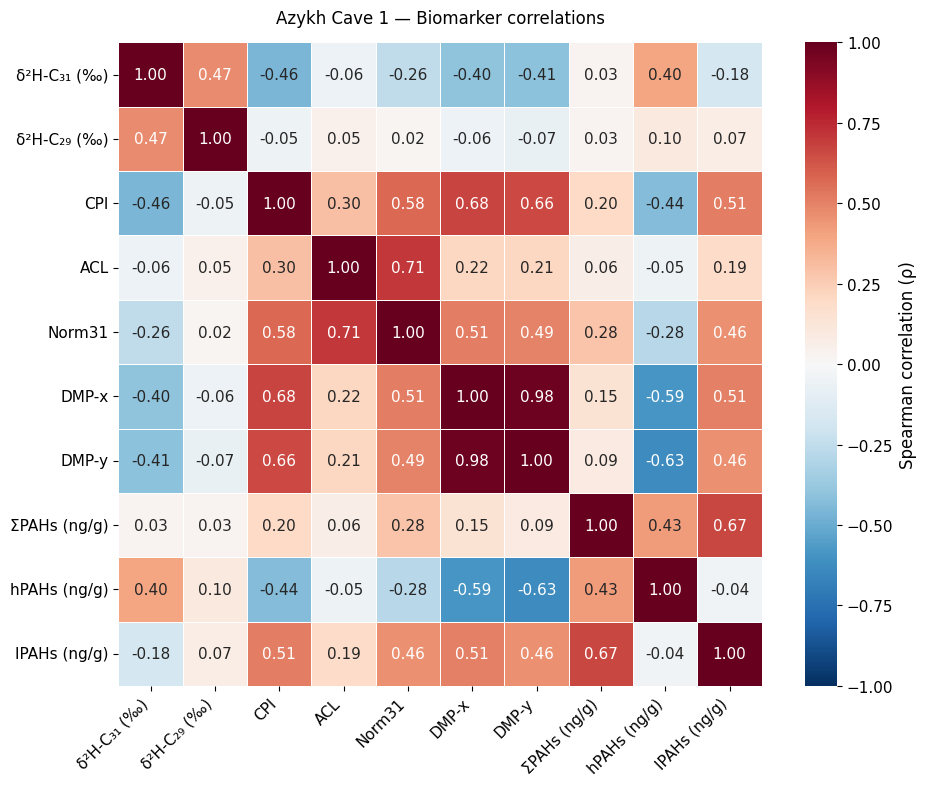

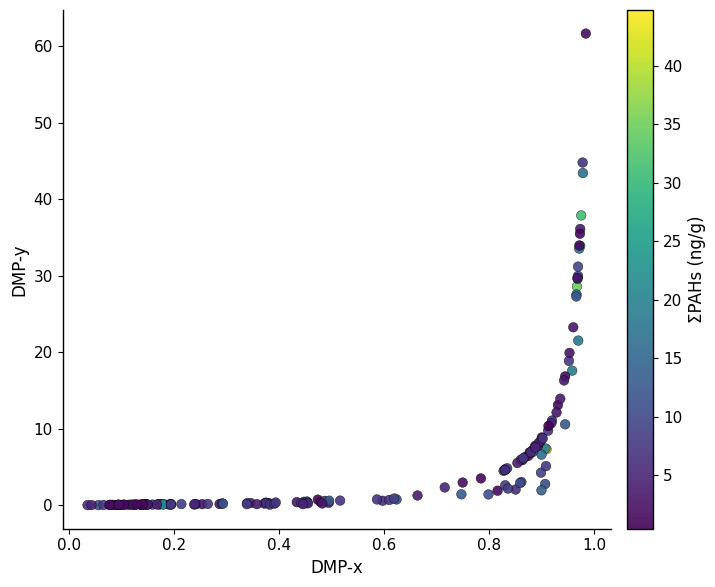

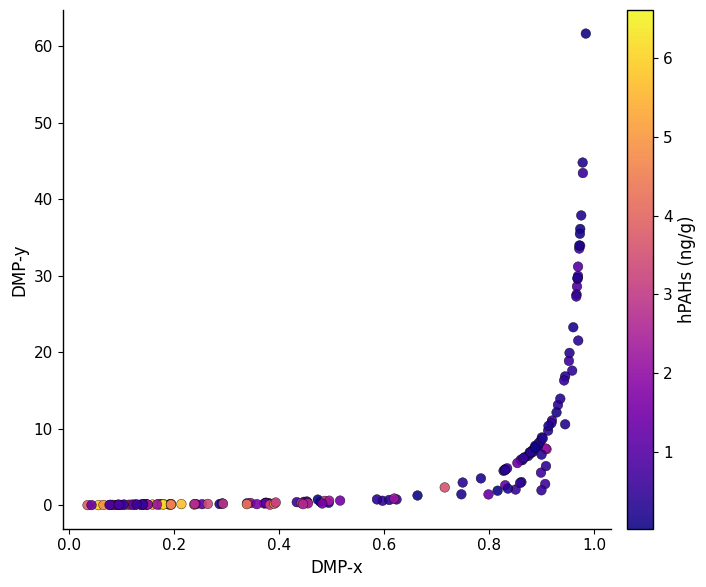

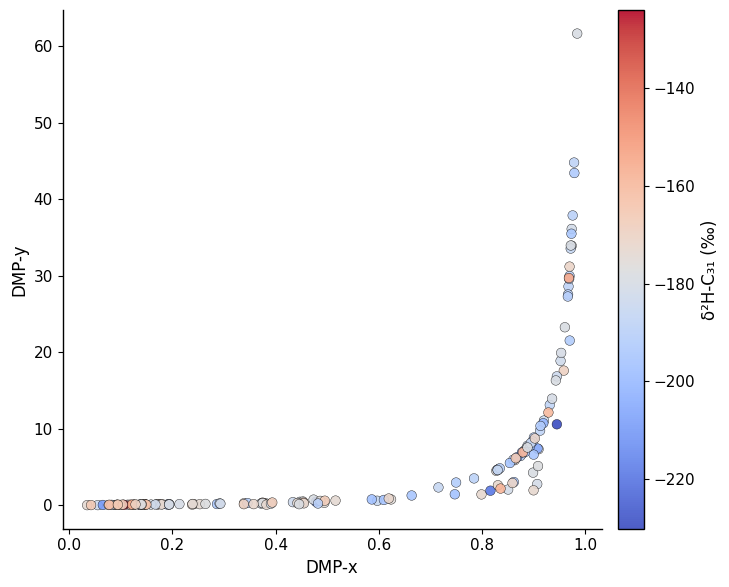

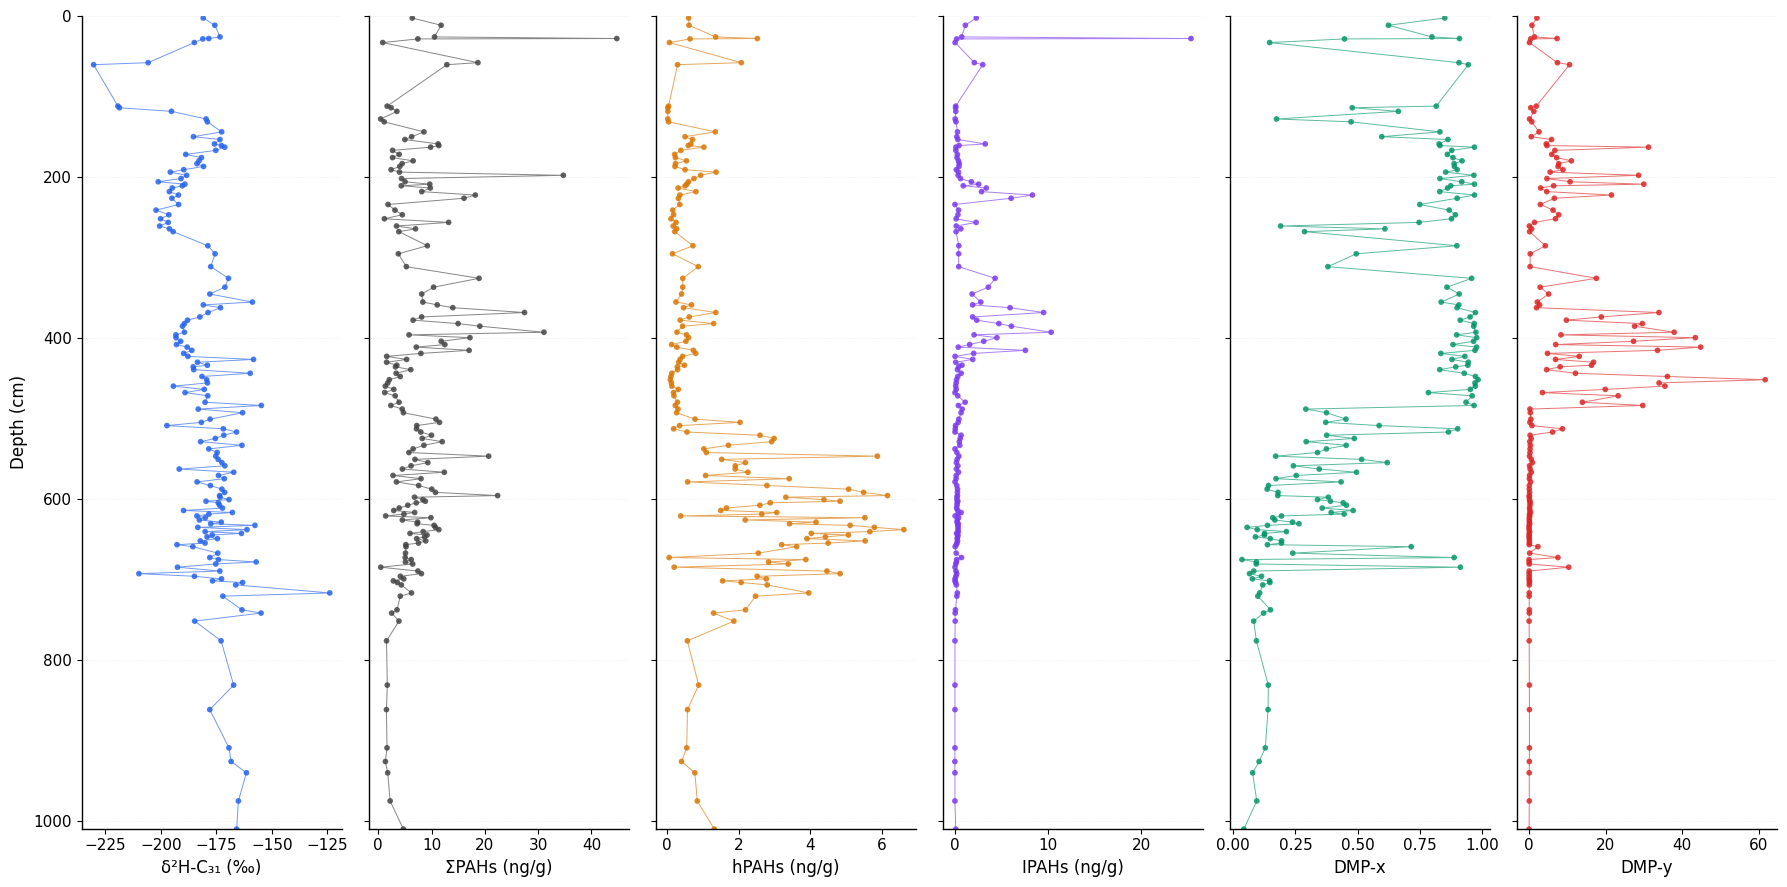

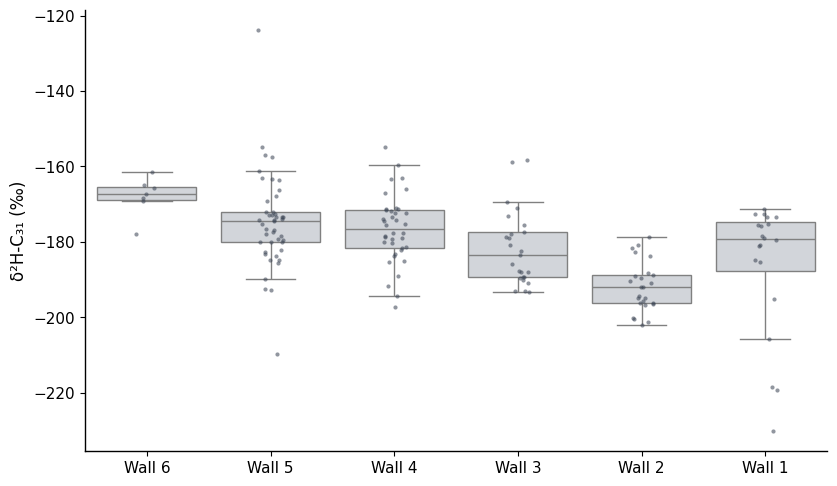

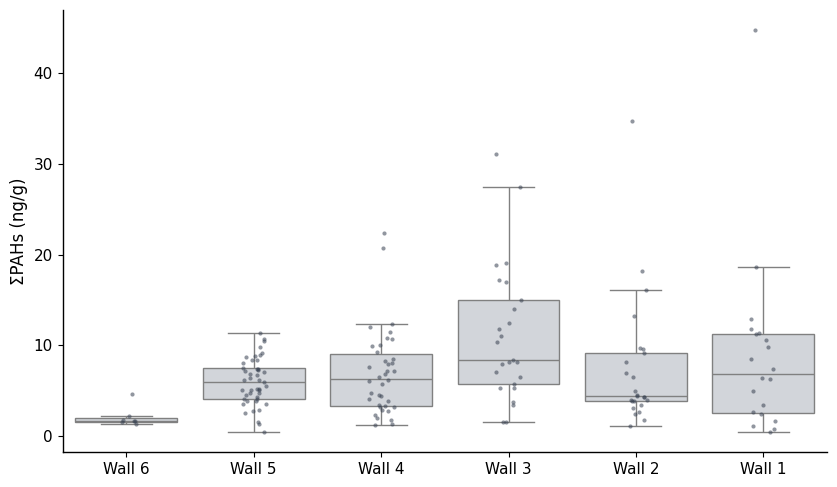

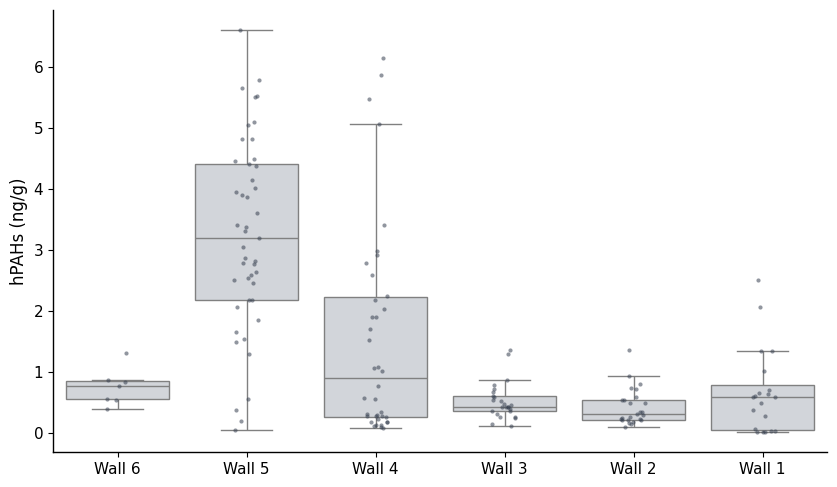

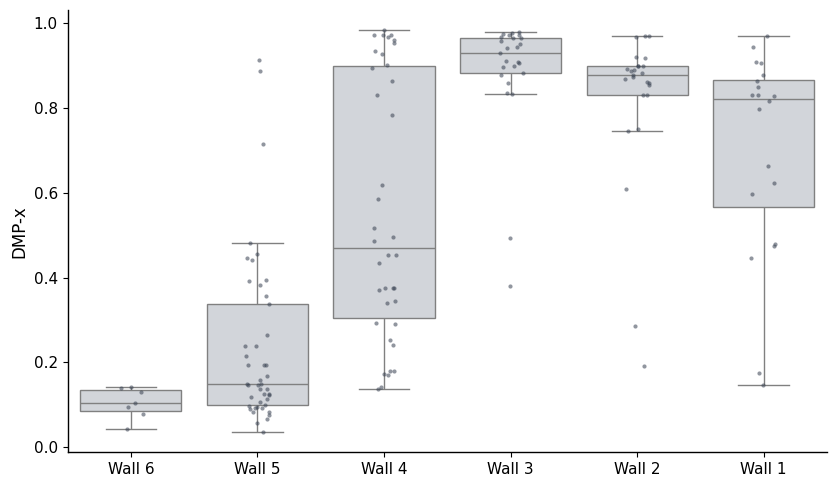

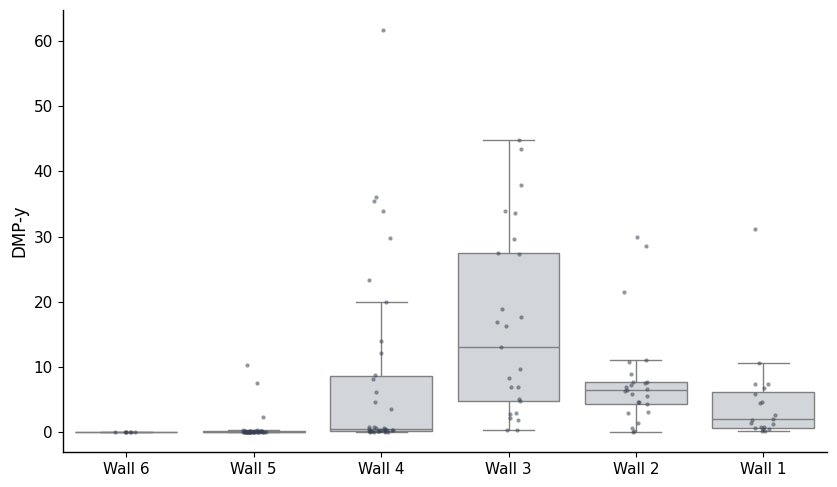

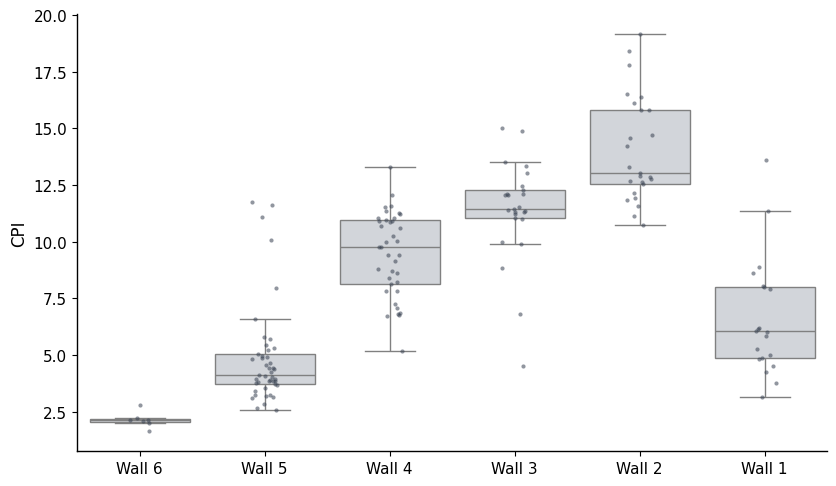

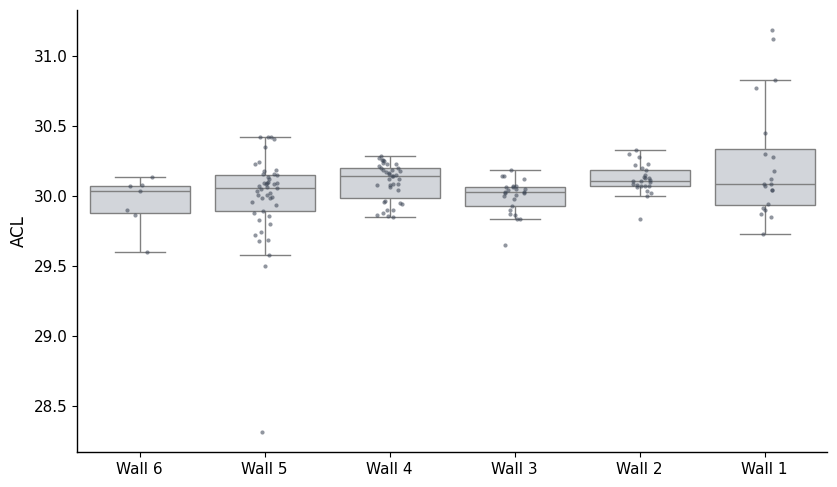

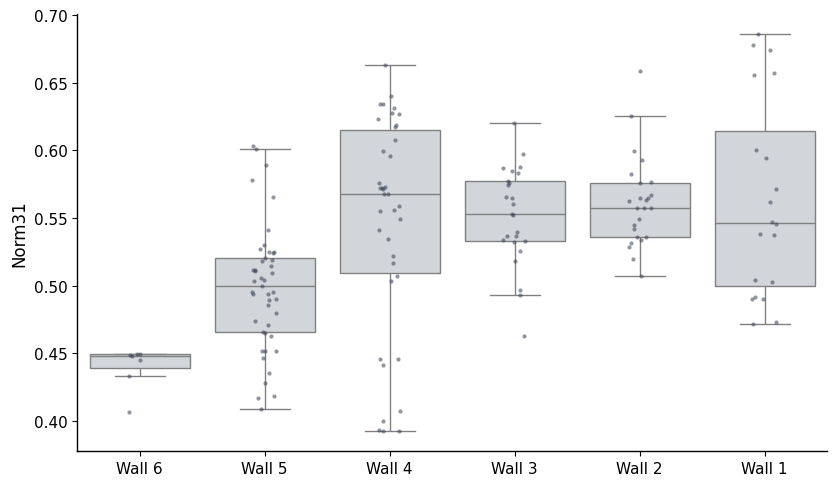


ANALYSIS COMPLETE
Original uploaded rows: 168
Cave rows analysed: 160
Output folder: /content/Azykh_Biomarker_Analysis
ZIP file: /content/Azykh_Biomarker_Analysis.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ================================================================
# AZYKH CAVE 1 — COMPLETE BIOMARKER STATISTICAL ANALYSIS
# ONE-CELL GOOGLE COLAB CODE
# ================================================================

!pip -q install scipy seaborn openpyxl

import os, re, csv, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr, rankdata, t as student_t
from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# ================================================================
# 1. OUTPUT FOLDER AND FIGURE STYLE
# ================================================================

OUT = "/content/Azykh_Biomarker_Analysis"
os.makedirs(OUT, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "axes.linewidth": 1.0,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": 400
})

WALL_ORDER = [f"Wall {i}" for i in range(6, 0, -1)]

LABELS = {
    "d2H_C31": "δ²H-C₃₁ (‰)",
    "d2H_C29": "δ²H-C₂₉ (‰)",
    "CPI": "CPI",
    "ACL": "ACL",
    "Norm31": "Norm31",
    "DMP_x": "DMP-x",
    "DMP_y": "DMP-y",
    "Total_PAH": "ΣPAHs (ng/g)",
    "hPAH": "hPAHs (ng/g)",
    "IPAH": "IPAHs (ng/g)"
}

# ================================================================
# 2. UPLOAD YOUR BIOMARKER CSV OR EXCEL FILE
# ================================================================

print("Upload Biomarker data (1).csv or an Excel version.")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded.")

filename = list(uploaded.keys())[0]

def read_file(path):
    if path.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(path)

    if not path.lower().endswith(".csv"):
        raise ValueError("Upload a CSV or Excel file.")

    # Your previous file was semicolon-separated.
    # Try semicolon first, then other common delimiters.
    for enc in ["utf-8-sig", "cp1252", "latin1"]:
        for sep in [";", ",", "\t", "|"]:
            try:
                temp = pd.read_csv(
                    path,
                    sep=sep,
                    encoding=enc,
                    engine="python",
                    on_bad_lines="error"
                )

                if "Sample ID" in temp.columns or (
                    "Depth" in temp.columns and
                    "DMP(x)" in temp.columns
                ):
                    print("Detected delimiter:", repr(sep))
                    return temp

            except (UnicodeDecodeError, pd.errors.ParserError):
                continue

    raise ValueError(
        "CSV could not be read correctly. "
        "Open the file in Excel and save as XLSX."
    )

df = read_file(filename)
df.columns = df.columns.astype(str).str.strip()

print("\nLoaded:", filename)
print("Original rows:", len(df))
print("Original columns:", len(df.columns))
print(list(df.columns))

# ================================================================
# 3. RENAME YOUR ACTUAL COLUMNS
# ================================================================

rename_map = {
    "Sample ID": "Sample",
    "Depth": "Depth",
    "δ H31 wax (‰)": "d2H_C31",
    "δ H29 wax (‰)": "d2H_C29",
    "CPI": "CPI",
    "ACL": "ACL",
    "Norm 31": "Norm31",
    "DMP(x)": "DMP_x",
    "DMP(y)": "DMP_y",
    "LMW/total": "LMW_total",
    "Ret/3-ring": "Ret_3ring",
    r"[PAHs]\(ng/g)": "Total_PAH",
    "[PAHs](ng/g)": "Total_PAH",
    "hPAHs  (ng/g)": "hPAH",
    "hPAHs (ng/g)": "hPAH",
    "IPAHs(ng/g)": "IPAH",
    "IPAHs (ng/g)": "IPAH",
    "Walls": "Wall"
}

main = df.rename(columns=rename_map).copy()

required = [
    "Sample", "Depth", "Wall",
    "DMP_x", "DMP_y",
    "Total_PAH", "hPAH", "IPAH",
    "d2H_C31", "d2H_C29"
]

missing = [c for c in required if c not in main.columns]

if missing:
    raise ValueError(
        f"Missing columns after renaming: {missing}\n"
        f"Available columns: {list(main.columns)}"
    )

# ================================================================
# 4. CLEAN NUMERIC VALUES AND WALL LABELS
# ================================================================

numeric_cols = [
    "Depth", "d2H_C31", "d2H_C29",
    "CPI", "ACL", "Norm31",
    "DMP_x", "DMP_y",
    "Total_PAH", "hPAH", "IPAH",
    "LMW_total", "Ret_3ring"
]

for col in numeric_cols:
    if col in main.columns:
        main[col] = pd.to_numeric(
            main[col].astype(str)
            .str.replace(",", ".", regex=False)
            .str.replace("‰", "", regex=False)
            .str.strip(),
            errors="coerce"
        )

wall_numbers = (
    main["Wall"].astype(str)
    .str.extract(r"(?i)(?:wall|w)?\s*[-_ ]*([1-6])")[0]
)

main["Wall"] = wall_numbers.map(
    lambda x: f"Wall {x}" if pd.notna(x) else np.nan
)

# Keep only recognized cave walls and valid depths.
# This excludes modern samples with no cave wall.
original_count = len(main)

main = main[
    main["Wall"].isin(WALL_ORDER) &
    main["Depth"].notna()
].copy()

main = main.sort_values("Depth").reset_index(drop=True)

print("\n==========================================")
print("DATA QUALITY SUMMARY")
print("==========================================")

print("Original rows:", original_count)
print("Cave rows retained:", len(main))
print("Excluded rows:", original_count - len(main))

print("\nNon-missing measurements:")
print(main[numeric_cols].count().to_string())

print("\nSamples per wall:")
print(main["Wall"].value_counts().reindex(WALL_ORDER))

print("\nPreview:")
display(main.head())

main.to_csv(
    f"{OUT}/01_Cleaned_Biomarker_Data.csv",
    index=False
)

# ================================================================
# 5. SPEARMAN CORRELATIONS
# ================================================================

variables = [
    c for c in [
        "d2H_C31", "d2H_C29",
        "CPI", "ACL", "Norm31",
        "DMP_x", "DMP_y",
        "Total_PAH", "hPAH", "IPAH"
    ]
    if c in main.columns
]

def spearman_test(data, a, b):
    sub = data[[a, b]].dropna()
    n = len(sub)

    if n < 4 or sub[a].nunique() < 2 or sub[b].nunique() < 2:
        return n, np.nan, np.nan

    rho, p = spearmanr(sub[a], sub[b])
    return n, float(rho), float(p)

correlation_rows = []

for i, a in enumerate(variables):
    for b in variables[i+1:]:
        n, rho, p = spearman_test(main, a, b)

        correlation_rows.append({
            "Variable_1": a,
            "Variable_2": b,
            "N": n,
            "Spearman_rho": rho,
            "p_value": p
        })

corr_df = pd.DataFrame(correlation_rows)

# Benjamini-Hochberg FDR correction for multiple tests.
def add_fdr(df, pcol="p_value"):
    result = df.copy()
    result["FDR_q"] = np.nan

    valid = result[pcol].notna()
    p = result.loc[valid, pcol].to_numpy()
    m = len(p)

    if m:
        order = np.argsort(p)
        ranked = p[order] * m / np.arange(1, m+1)
        adjusted = np.minimum.accumulate(ranked[::-1])[::-1]
        adjusted = np.clip(adjusted, 0, 1)

        restored = np.empty(m)
        restored[order] = adjusted
        result.loc[valid, "FDR_q"] = restored

    return result

corr_df = add_fdr(corr_df)

corr_df.to_csv(
    f"{OUT}/02_All_Spearman_Correlations.csv",
    index=False
)

print("\n==========================================")
print("SPEARMAN CORRELATIONS")
print("==========================================")

display(
    corr_df.sort_values("p_value").round(4)
)

# ================================================================
# 6. DEPTH-ADJUSTED PARTIAL SPEARMAN
# ================================================================

def partial_spearman(data, a, b):

    sub = data[[a, b, "Depth"]].dropna()
    n = len(sub)

    if n < 5 or any(
        sub[c].nunique() < 2
        for c in [a, b, "Depth"]
    ):
        return n, np.nan, np.nan

    x = rankdata(sub[a])
    y = rankdata(sub[b])
    z = rankdata(sub["Depth"])

    X = np.column_stack([np.ones(n), z])

    residual_x = x - X @ np.linalg.lstsq(
        X, x, rcond=None
    )[0]

    residual_y = y - X @ np.linalg.lstsq(
        X, y, rcond=None
    )[0]

    if np.std(residual_x) == 0 or np.std(residual_y) == 0:
        return n, np.nan, np.nan

    r = np.corrcoef(residual_x, residual_y)[0, 1]

    degrees = n - 3

    statistic = r * np.sqrt(
        degrees / max(1e-12, 1-r*r)
    )

    p = 2 * student_t.sf(abs(statistic), degrees)

    return n, float(r), float(p)

partial_rows = []

for i, a in enumerate(variables):
    for b in variables[i+1:]:

        n, rho, p = partial_spearman(main, a, b)

        partial_rows.append({
            "Variable_1": a,
            "Variable_2": b,
            "N": n,
            "Partial_rho": rho,
            "p_value": p
        })

partial_df = add_fdr(pd.DataFrame(partial_rows))

partial_df.to_csv(
    f"{OUT}/03_Depth_Adjusted_Correlations.csv",
    index=False
)

print("\n==========================================")
print("DEPTH-ADJUSTED CORRELATIONS")
print("==========================================")

display(
    partial_df.sort_values("p_value").round(4)
)

# ================================================================
# 7. WALL-BASED CORRELATIONS
# ================================================================

focus_pairs = [
    ("DMP_x", "d2H_C31"),
    ("DMP_y", "d2H_C31"),
    ("DMP_x", "Total_PAH"),
    ("DMP_y", "Total_PAH"),
    ("DMP_x", "hPAH"),
    ("DMP_y", "hPAH"),
    ("hPAH", "d2H_C31"),
    ("Total_PAH", "d2H_C31"),
    ("CPI", "d2H_C31"),
    ("ACL", "d2H_C31"),
    ("Norm31", "d2H_C31")
]

wall_rows = []

for wall in WALL_ORDER:

    subset = main[main["Wall"] == wall]

    for a, b in focus_pairs:
        if a not in subset or b not in subset:
            continue

        n, rho, p = spearman_test(subset, a, b)

        wall_rows.append({
            "Wall": wall,
            "Variable_1": a,
            "Variable_2": b,
            "N": n,
            "Spearman_rho": rho,
            "p_value": p
        })

wall_df = pd.DataFrame(wall_rows)
wall_df = add_fdr(wall_df)

wall_df.to_csv(
    f"{OUT}/04_Wall_Based_Correlations.csv",
    index=False
)

print("\n==========================================")
print("WALL-BASED CORRELATIONS")
print("==========================================")

display(wall_df.round(4))

# ================================================================
# 8. WALL-BASED DESCRIPTIVE STATISTICS
# ================================================================

descriptive = (
    main.groupby("Wall")[variables]
    .agg(["count", "min", "max", "mean", "median", "std"])
    .reindex(WALL_ORDER)
)

descriptive.to_csv(
    f"{OUT}/05_Wall_Descriptive_Statistics.csv"
)

print("\n==========================================")
print("WALL DESCRIPTIVE STATISTICS")
print("==========================================")

display(descriptive.round(3))

# ================================================================
# 9. CORRELATION HEATMAP
# ================================================================

matrix = main[variables].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.4,
    cbar_kws={
        "label": "Spearman correlation (ρ)"
    },
    ax=ax
)

ax.set_xticklabels(
    [LABELS.get(c, c) for c in variables],
    rotation=45,
    ha="right"
)

ax.set_yticklabels(
    [LABELS.get(c, c) for c in variables],
    rotation=0
)

ax.set_title(
    "Azykh Cave 1 — Biomarker correlations",
    pad=14
)

fig.tight_layout()

fig.savefig(
    f"{OUT}/Fig1_Correlation_Heatmap.png",
    dpi=400
)
fig.savefig(
    f"{OUT}/Fig1_Correlation_Heatmap.pdf"
)

plt.show()

# ================================================================
# 10. DMP SCATTERPLOTS
# ================================================================

def dmp_scatter(color_col, filename, cmap):

    sub = main[
        ["DMP_x", "DMP_y", color_col]
    ].dropna()

    if sub.empty:
        print("No data for:", color_col)
        return

    fig, ax = plt.subplots(figsize=(7.5, 6))

    points = ax.scatter(
        sub["DMP_x"],
        sub["DMP_y"],
        c=sub[color_col],
        cmap=cmap,
        s=48,
        alpha=0.9,
        edgecolors="black",
        linewidths=0.3
    )

    cb = fig.colorbar(
        points, ax=ax, pad=0.025
    )

    cb.set_label(LABELS.get(color_col, color_col))

    ax.set_xlabel("DMP-x")
    ax.set_ylabel("DMP-y")

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)

    fig.tight_layout()

    fig.savefig(
        f"{OUT}/{filename}.png",
        dpi=400
    )
    fig.savefig(
        f"{OUT}/{filename}.pdf"
    )

    plt.show()

dmp_scatter(
    "Total_PAH",
    "Fig2_DMP_Total_PAH",
    "viridis"
)

dmp_scatter(
    "hPAH",
    "Fig3_DMP_hPAH",
    "plasma"
)

dmp_scatter(
    "d2H_C31",
    "Fig4_DMP_Hydrogen_Isotopes",
    "coolwarm"
)

# ================================================================
# 11. STRATIGRAPHIC PROFILE — ISOTOPES, PAHs AND DMP
# ================================================================

profile_vars = [
    "d2H_C31",
    "Total_PAH",
    "hPAH",
    "IPAH",
    "DMP_x",
    "DMP_y"
]

fig, axes = plt.subplots(
    1, len(profile_vars),
    figsize=(18, 9),
    sharey=True
)

colors = [
    "#2563eb",
    "#444444",
    "#d97706",
    "#7c3aed",
    "#059669",
    "#dc2626"
]

for ax, var, color in zip(
    axes, profile_vars, colors
):

    sub = main[
        ["Depth", var]
    ].dropna().sort_values("Depth")

    ax.plot(
        sub[var],
        sub["Depth"],
        color=color,
        linewidth=0.7,
        alpha=0.65
    )

    ax.scatter(
        sub[var],
        sub["Depth"],
        color=color,
        s=17,
        alpha=0.85,
        edgecolors="none"
    )

    ax.set_xlabel(LABELS.get(var, var))

    ax.grid(
        axis="y",
        linestyle=":",
        linewidth=0.5,
        alpha=0.3
    )

    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Depth (cm)")
axes[0].set_ylim(1010, 0)

fig.tight_layout()

fig.savefig(
    f"{OUT}/Fig5_Stratigraphic_Profiles.png",
    dpi=400
)
fig.savefig(
    f"{OUT}/Fig5_Stratigraphic_Profiles.pdf"
)

plt.show()

# ================================================================
# 12. WALL-BASED BOXPLOTS
# ================================================================

for var in [
    "d2H_C31",
    "Total_PAH",
    "hPAH",
    "DMP_x",
    "DMP_y",
    "CPI",
    "ACL",
    "Norm31"
]:

    if var not in main.columns:
        continue

    fig, ax = plt.subplots(figsize=(8.5, 5))

    sns.boxplot(
        data=main,
        x="Wall",
        y=var,
        order=WALL_ORDER,
        color="#d1d5db",
        showfliers=False,
        ax=ax
    )

    sns.stripplot(
        data=main,
        x="Wall",
        y=var,
        order=WALL_ORDER,
        color="#374151",
        size=3,
        alpha=0.55,
        ax=ax
    )

    ax.set_xlabel("")
    ax.set_ylabel(LABELS.get(var, var))

    ax.spines[["top", "right"]].set_visible(False)

    fig.tight_layout()

    fig.savefig(
        f"{OUT}/Fig_Walls_{var}.png",
        dpi=400
    )
    fig.savefig(
        f"{OUT}/Fig_Walls_{var}.pdf"
    )

    plt.show()

# ================================================================
# 13. EXPORT ALL RESULTS
# ================================================================

zip_path = "/content/Azykh_Biomarker_Analysis.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for file in os.listdir(OUT):

        path = os.path.join(OUT, file)

        if os.path.isfile(path):
            archive.write(path, arcname=file)

print("\n" + "=" * 60)
print("ANALYSIS COMPLETE")
print("=" * 60)

print("Original uploaded rows:", original_count)
print("Cave rows analysed:", len(main))
print("Output folder:", OUT)
print("ZIP file:", zip_path)

files.download(zip_path)
